# Ethanol long delay scans — 268 eV

FLASH2, beamtime 11024642. Analysis of config 1 `time_resolved` aggregates (GMD × delay × TOF).

Run from the repository root or `analysis/notebooks`, using the FLASH Remote kernel. Select the scans and calibration settings in section 1. Run the notebook from top to bottom. Delay and TOF bin edges are read from the H5 files; changing the aggregate binning does not require changing the plotting code. Files pooled together must have identical delay and TOF edges.

| Section | Analysis |
|---|---|
| 1–2 | Load scans, calibrated axes and reference |
| 3–4 | Acquisition statistics, GMD and Gotthard (VLS) stability |
| 5–6 | Electron and ion spectra and delay maps |
| 7 | Temporal traces and GMD-bin comparison |
| 8 | Comparison between scans |
| 9 | Electron–electron and electron–ion covariance |
| 10 | Acquisition time estimate |

Only first moments are loaded initially. Section 9 reads second moments one GMD-delay cell at a time and can be run separately after sections 1–2. It may take longer and use more memory for finer binning.

## 1. Load data

In [35]:
import sys
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt

# Works from analysis/notebooks or the repository root.
repo = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'analysis/scripts/config.py').is_file()), None)
if repo is None:
    raise FileNotFoundError('Run from the repository root or analysis/notebooks')
scripts = str(repo / 'analysis/scripts')
if scripts not in sys.path:
    sys.path.insert(0, scripts)

from config import COMBINED_DIR
import calibration

# Select all long scans, or replace FILES with a list of specific paths.
FILES = sorted(COMBINED_DIR.glob('*Ethanol_delay_scan_long*268eV*_aggregates_tr.h5'))

# FILES = FILES[-1:]  # latest scan only

VLS_CAL_FILE = COMBINED_DIR / 'run60560_Ethanol_undulator_scan_2808016357.h5'

GMD_BINS = None              # None: all; e.g. [0, 1] for lowest percentile bins
FS_PER_STAGE_UNIT = 0.349 / 1000
Z_ZERO = 0                   # stage units; adjust when time zero is established
DELAY_SIGN = 1               # +1 or -1, depending on the delay convention
NORMALISE = 'per_uJ'         # 'per_uJ' or 'per_shot'

# Optional measured acquisition times in minutes, keyed by aggregate filename.
# Otherwise estimate the time from the first and last combined-file train IDs.
SCAN_MINUTES = {}
TRAIN_RATE = 10              # Hz

print(f'{len(FILES)} files selected:')
for path in FILES:
    print(path.name)

4 files selected:
Ethanol_delay_scan_long_1_268eV_2808353754_aggregates_tr.h5
Ethanol_delay_scan_long_2_268eV_2808380252_aggregates_tr.h5
Ethanol_delay_scan_long_3_268eV_2808406908_aggregates_tr.h5
Ethanol_delay_scan_long_4_268eV_2808435816_aggregates_tr.h5


In [36]:
# Read only the first moments and bin edges. D, C and G are means per shot.
if not FILES:
    raise FileNotFoundError('No delay aggregates found in ' + str(COMBINED_DIR))

scans = {}
axes = {}
for path in FILES:
    path = Path(path)
    with h5py.File(path, 'r') as f:
        if f.attrs['config'] != 1 or f.attrs['mode'] != 'time_resolved':
            raise ValueError(f'{path.name}: expected config 1 time_resolved aggregates')
        edges = {key: f[key][:] for key in ('z_edges', 'tof_edges', 'ion_tof_edges')}
        if not axes:
            axes = edges
        elif any(not np.array_equal(edges[key], axes[key]) for key in axes):
            raise ValueError(f'{path.name}: different delay or TOF edges. Select compatible scans.')

        n = f['n_per_bin'][:]
        D, C, G = f['D'][:], f['C'][:], f['G'][:]
        gmd_edges = f['gmd_edges'][:]
        attrs = dict(f.attrs)

    # Empty cells contain NaNs. Ignore them, not NaNs in populated cells.
    if any(not np.isfinite(a[n > 0]).all() for a in (D, C, G)):
        raise ValueError(f'{path.name}: non-finite means in populated bins')
    bins = slice(None) if GMD_BINS is None else GMD_BINS
    n, D, C, G = n[bins], D[bins], C[bins], G[bins]
    # Convert means to sums before collapsing the GMD dimension.
    e = np.where(n[..., None] > 0, D, 0) * n[..., None]
    i = np.where(n[..., None] > 0, C, 0) * n[..., None]
    g = np.where(n > 0, G, 0) * n

    # Acquisition duration: read just the two train-ID endpoints.
    minutes = SCAN_MINUTES.get(path.name, np.nan)
    source = Path(attrs.get('input_h5', ''))
    if not source.is_file():
        source = COMBINED_DIR / path.name.replace('_aggregates_tr.h5', '.h5')
    if not np.isfinite(minutes) and source.is_file():
        with h5py.File(source, 'r') as f:
            if 'tID' in f and len(f['tID']):
                minutes = (int(f['tID'][-1]) - int(f['tID'][0]) + 1) / TRAIN_RATE / 60

    scans[path.name] = dict(n=n.sum(axis=0), e=e.sum(axis=0),
                            i=i.sum(axis=0), g=g.sum(axis=0),
                            minutes=minutes, gmd_edges=gmd_edges, attrs=attrs)
    s = scans[path.name]
    print(f'\n{path.name}')
    print(f'  shots = {s["n"].sum():,}; e = {s["e"].sum():,.0f}; i = {s["i"].sum():,.0f}')
    print(f'  occupied delay bins = {np.count_nonzero(s["n"])} / {len(s["n"])}; time = {minutes:.1f} min')
    print('  GMD edges (uJ):', np.round(gmd_edges, 3))
    print('  skipped z outside / NaN:', attrs.get('n_skipped_z_oor', '?'), attrs.get('n_skipped_z_nan', '?'))
    print('  skipped max hits:', attrs.get('n_skipped_max_hits', '?'))

# GMD percentile edges can differ by file. Pool counts, not means.
combined = {key: np.sum([s[key] for s in scans.values()], axis=0)
            for key in ('n', 'e', 'i', 'g')}
combined['minutes'] = sum(s['minutes'] for s in scans.values())
scans_raw, combined_raw = scans, combined
if GMD_BINS is not None:
    print("Note: selected GMD indices refer to each scan's own edges.")


Ethanol_delay_scan_long_1_268eV_2808353754_aggregates_tr.h5
  shots = 2,414,666; e = 1,734,860; i = 434,770
  occupied delay bins = 32 / 32; time = 41.8 min
  GMD edges (uJ): [0.02  0.076 0.145 0.234 0.398 3.901]
  skipped z outside / NaN: 0 0
  skipped max hits: 21

Ethanol_delay_scan_long_2_268eV_2808380252_aggregates_tr.h5
  shots = 2,407,157; e = 1,912,852; i = 442,601
  occupied delay bins = 32 / 32; time = 41.8 min
  GMD edges (uJ): [0.02  0.075 0.147 0.24  0.411 3.905]
  skipped z outside / NaN: 0 0
  skipped max hits: 30

Ethanol_delay_scan_long_3_268eV_2808406908_aggregates_tr.h5
  shots = 2,330,025; e = 1,783,654; i = 398,662
  occupied delay bins = 32 / 32; time = 41.8 min
  GMD edges (uJ): [0.02  0.068 0.136 0.225 0.389 4.111]
  skipped z outside / NaN: 0 0
  skipped max hits: 18

Ethanol_delay_scan_long_4_268eV_2808435816_aggregates_tr.h5
  shots = 2,439,601; e = 2,795,169; i = 530,573
  occupied delay bins = 32 / 32; time = 41.8 min
  GMD edges (uJ): [0.02  0.094 0.178 0

## 2. Calibrated axes

TOF is saved in 100 ps units; the calibration functions take ns. Transform bin edges (not just centres), reverse the electron spectrum, and divide by the actual widths for spectral density plots. Counts for statistics and integration are kept as counts/bin.

The delay conversion follows the supplied SDU configuration. Its sign and time zero still need experimental confirmation. The delay step is not the temporal resolution.

In [37]:
if DELAY_SIGN not in (-1, 1):
    raise ValueError('DELAY_SIGN must be +1 or -1')

z_edges = axes['z_edges']
delay_edges = DELAY_SIGN * (z_edges - Z_ZERO) * FS_PER_STAGE_UNIT
ke_edges = calibration.ke_of_tof(axes['tof_edges'] / 10)[::-1]
mq_edges = calibration.mq_of_tof(axes['ion_tof_edges'] / 10)

# Keep all plotted axes increasing. Copy dictionaries so this cell can be rerun.
scans = {name: dict(s) for name, s in scans_raw.items()}
combined = dict(combined_raw)
for s in [*scans.values(), combined]:
    s['e'] = s['e'][:, ::-1]
    if DELAY_SIGN == -1:
        for key in ('n', 'e', 'i', 'g'):
            s[key] = s[key][::-1]
if DELAY_SIGN == -1:
    delay_edges = delay_edges[::-1]

delay = (delay_edges[:-1] + delay_edges[1:]) / 2
ke = (ke_edges[:-1] + ke_edges[1:]) / 2
mq = (mq_edges[:-1] + mq_edges[1:]) / 2
dke, dmq = np.diff(ke_edges), np.diff(mq_edges)

if any(np.any(~np.isfinite(edges)) or np.any(np.diff(edges) <= 0)
       for edges in (delay_edges, ke_edges, mq_edges)):
    raise ValueError('Calibrated edges must be finite and increasing')

# Safe division: empty exposure gives NaN, not zero signal.
def divide(a, b):
    a, b = np.broadcast_arrays(a, b)
    return np.divide(a, b, out=np.full(a.shape, np.nan, dtype=float), where=b > 0)

exposure_key = {'per_uJ': 'g', 'per_shot': 'n'}[NORMALISE]
unit = {'per_uJ': r'$\mu$J', 'per_shot': 'shot'}[NORMALISE]

print(f'Delay: {delay_edges[0]:.3f} to {delay_edges[-1]:.3f} fs, {len(delay)} bins')
print('Delay bin widths (fs):', np.unique(np.round(np.diff(delay_edges), 6)))
print(f'KE: {ke_edges[0]:.2f} to {ke_edges[-1]:.2f} eV')
print(f'm/q: {mq_edges[0]:.2f} to {mq_edges[-1]:.2f} u/e')

Delay: -4.889 to 59.333 fs, 32 bins
Delay bin widths (fs): [2.006968]
KE: 1.00 to 290.29 eV
m/q: 0.21 to 50.43 u/e


### Delay reference

Relative signals are measured against the exposure-weighted mean in the selected delay interval, not a pump-off spectrum.

In [38]:
DELAY_BASELINE = None        # None: all delays
# DELAY_BASELINE = (-4, 0)  # example in fs; choose after inspecting the scan

if DELAY_BASELINE is None:
    ref_mask = np.ones(len(delay), dtype=bool)
else:
    lo, hi = DELAY_BASELINE
    ref_mask = (delay >= lo) & (delay < hi)

if not ref_mask.any():
    raise ValueError('No bins in the selected delay reference')

def delay_reference(counts, exposure):
    return divide(counts[ref_mask].sum(axis=0),
                  exposure[ref_mask].sum())

idx = np.flatnonzero(ref_mask)
print(f'Reference: {delay_edges[idx[0]]:.2f} to '
      f'{delay_edges[idx[-1]+1]:.2f} fs')

Reference: -4.89 to 59.33 fs


## 3. Acquisition statistics

Counts are reconstructed after the aggregation cuts, within the recorded TOF range. They are detected hits, not incident electrons or the number of coincidence events.

The high-energy electron ROI includes direct photoelectrons as well as possible Auger signal; it is not a pure Auger yield.

Shots            total    9,591,449 | min  260,949 | median  301,738 | max  305,185
Electron counts  total    8,226,535 | min  222,033 | median  252,986 | max  309,378
Electron ROI counts total    1,231,259 | min   32,722 | median   37,951 | max   45,765
Ion counts       total    1,806,606 | min   47,737 | median   55,976 | max   65,973


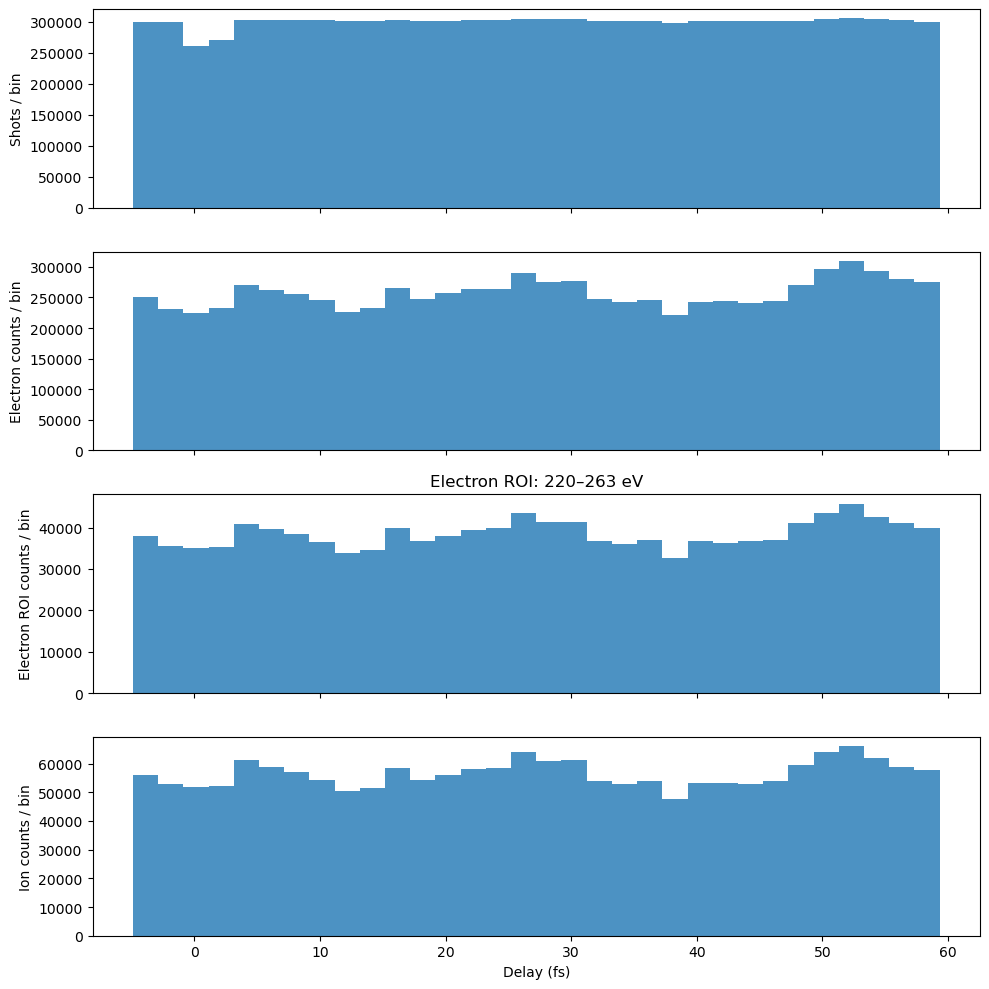

In [39]:
COUNT_ROI = (220, 263)

mask = (ke >= COUNT_ROI[0]) & (ke < COUNT_ROI[1])
if not mask.any():
    raise ValueError(f'No electron bins in {COUNT_ROI} eV')
roi_counts = combined['e'][:, mask].sum(axis=1)

fig, ax = plt.subplots(4, 1, figsize=(10, 10), sharex=True)

for a, y, label in zip(ax, [combined['n'], combined['e'].sum(axis=1), roi_counts,
                           combined['i'].sum(axis=1)],
                      ['Shots', 'Electron counts', 'Electron ROI counts', 'Ion counts']):
    a.bar(delay, y, width=np.diff(delay_edges), alpha=0.8)
    a.set_ylabel(label + ' / bin')
    print(f'{label:16s} total {y.sum():12,.0f} | min {y.min():8,.0f} | '
          f'median {np.median(y):8,.0f} | max {y.max():8,.0f}')

ax[2].set_title(f'Electron ROI: {COUNT_ROI[0]}–{COUNT_ROI[1]} eV')
ax[-1].set_xlabel('Delay (fs)')
fig.tight_layout()
plt.show()

## 4. FEL stability

Per-µJ normalisation is a useful diagnostic but does not correct nonlinear detector response or changing GMD distributions. Ion detection also depends on bunch position (see handover).

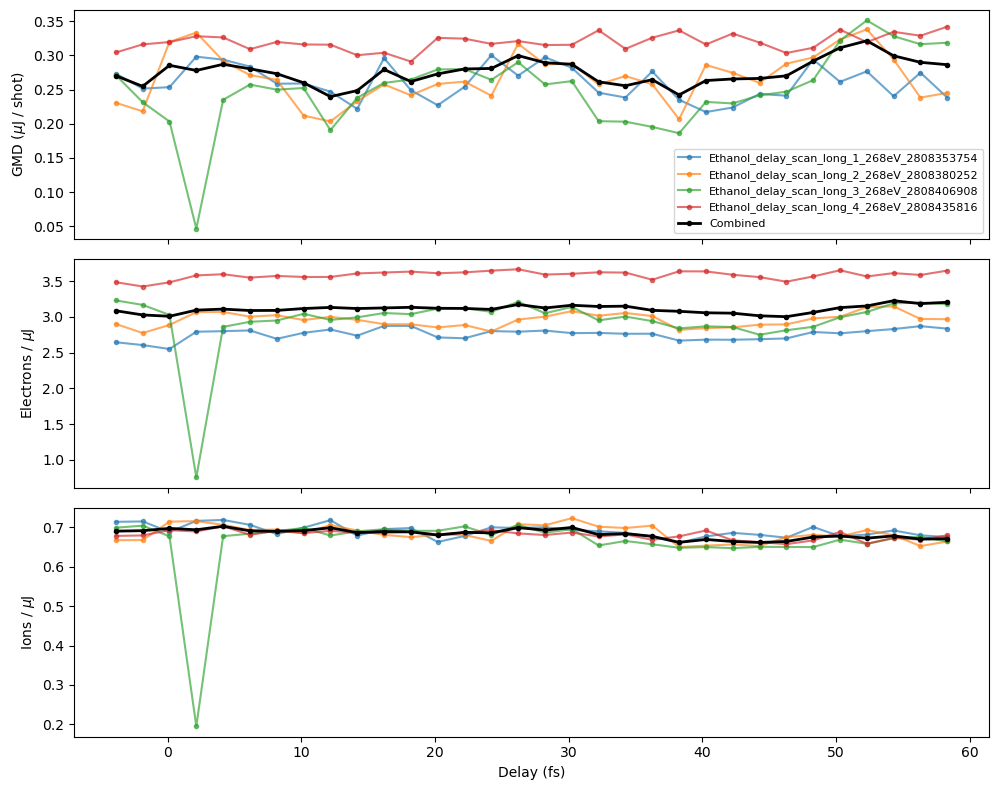

In [40]:
fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

for name, s in [*scans.items(), ('Combined', combined)]:
    label = 'Combined' if name == 'Combined' else name.replace('_aggregates_tr.h5', '')
    style = dict(color='k', linewidth=2) if name == 'Combined' else dict(alpha=0.65)
    ax[0].plot(delay, divide(s['g'], s['n']), '.-', label=label, **style)
    ax[1].plot(delay, divide(s['e'].sum(axis=1), s['g']), '.-', **style)
    ax[2].plot(delay, divide(s['i'].sum(axis=1), s['g']), '.-', **style)

ax[0].set_ylabel(r'GMD ($\mu$J / shot)')
ax[1].set_ylabel(r'Electrons / $\mu$J')
ax[2].set_ylabel(r'Ions / $\mu$J')
ax[0].legend(fontsize=8)
ax[-1].set_xlabel('Delay (fs)')
fig.tight_layout()
plt.show()

### 4.1 FEL spectral stability (Gotthard)

Load the mean VLS spectrum in each GMD-delay bin and use the photon-energy calibration from the ethanol undulator scan (run 60560). The map is intensity per µJ; the integrated spectrum is per shot. These are averaged spectra, not single-shot bandwidth or single-spike statistics. Skip these two cells if the VLS moments or calibration file are unavailable.

In [41]:
# ---- Load VLS aggregates --------------------------------------------------


vls_scans = {}
vls_pixels = None

for path in FILES:

    path = Path(path)

    with h5py.File(path, 'r') as f:

        if 'A' not in f:
            raise ValueError(f'{path.name}: no VLS aggregates stored')

        n = f['n_per_bin'][:]
        A = f['A'][:]
        pixels = f['vls_pixels'][:]

        if vls_pixels is None:
            vls_pixels = pixels
        else:
            np.testing.assert_array_equal(vls_pixels, pixels)

        np.testing.assert_array_equal(f['z_edges'][:], z_edges)

        if A.shape != (*n.shape, len(pixels)):
            raise ValueError(f'{path.name}: incompatible VLS shape')
        print(path.name, '| VLS shape:', A.shape)

    if not np.isfinite(A[n > 0]).all():
        raise ValueError(f'{path.name}: non-finite VLS means')

    # Same GMD selection as the electron and ion analysis.
    bins = slice(None) if GMD_BINS is None else GMD_BINS
    n, A = n[bins], A[bins]

    # Convert means to sums before collapsing the GMD axis.
    a = np.where(n[..., None] > 0, A, 0) * n[..., None]

    a = a.sum(axis=0)
    n = n.sum(axis=0)

    if DELAY_SIGN == -1:
        a, n = a[::-1], n[::-1]

    np.testing.assert_array_equal(n, scans[path.name]['n'])

    vls_scans[path.name] = dict(
        a=a,
        n=n,
        g=scans[path.name]['g']
    )

# Pool sums across scans.
vls_combined = {
    key: np.sum([s[key] for s in vls_scans.values()], axis=0)
    for key in ('a', 'n', 'g')
}

# ---- Photon-energy calibration -------------------------------------------

with h5py.File(VLS_CAL_FILE, 'r') as f:
    cal_coef = f['photon_energy/cal_coef'][:]
    cal_px = f['photon_energy/cal_centres'][:]
    cal_E = f['photon_energy/cal_energies'][:]

vls_energy = np.polyval(cal_coef, vls_pixels)

print('Calibration coefficients:', cal_coef)
print('Calibration RMS (eV):',
      np.sqrt(np.mean((np.polyval(cal_coef, cal_px) - cal_E)**2)))

print(f'VLS energy range: {vls_energy.min():.2f}–'
      f'{vls_energy.max():.2f} eV')

# Mean VLS spectrum per shot and per delay bin.
vls_mean = divide(vls_combined['a'],
                  vls_combined['n'][:, None])

print('Combined VLS shape:', vls_mean.shape)

Ethanol_delay_scan_long_1_268eV_2808353754_aggregates_tr.h5 | VLS shape: (5, 32, 380)
Ethanol_delay_scan_long_2_268eV_2808380252_aggregates_tr.h5 | VLS shape: (5, 32, 380)
Ethanol_delay_scan_long_3_268eV_2808406908_aggregates_tr.h5 | VLS shape: (5, 32, 380)
Ethanol_delay_scan_long_4_268eV_2808435816_aggregates_tr.h5 | VLS shape: (5, 32, 380)
Calibration coefficients: [-5.90511927e-02  2.98986902e+02]
Calibration RMS (eV): 0.07455633448733763
VLS energy range: 261.84–284.22 eV
Combined VLS shape: (32, 380)


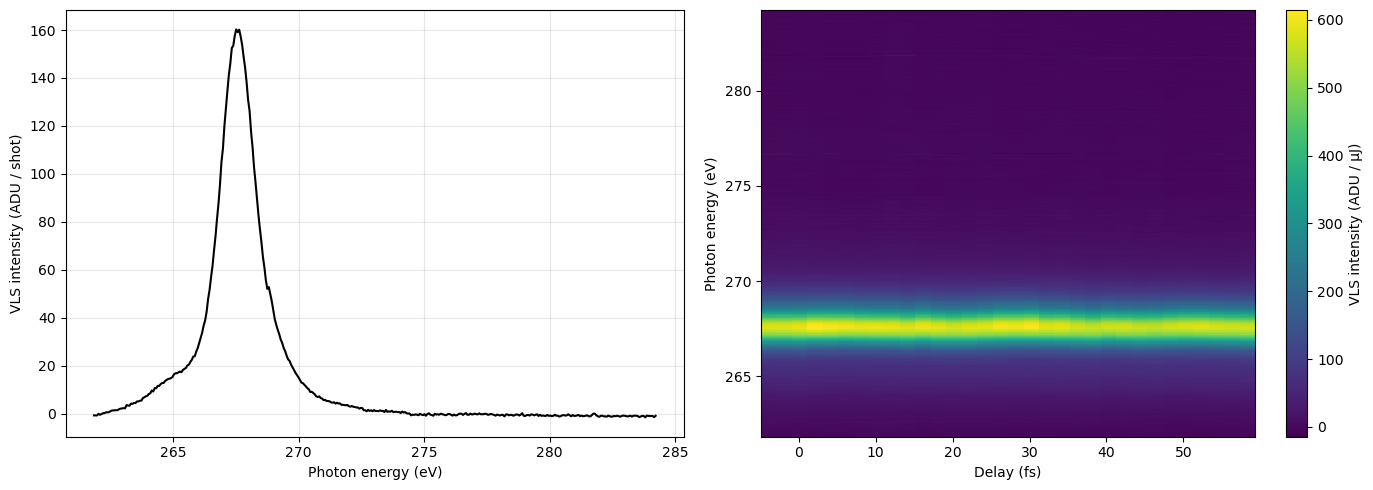

In [42]:
# ---- Average VLS spectrum and delay map -----------------------------------

from matplotlib.ticker import MultipleLocator

order = np.argsort(vls_energy)
E = vls_energy[order]

# Integrated spectrum per shot.
vls_ref = divide(vls_combined['a'].sum(axis=0),
                 vls_combined['n'].sum())

# VLS intensity per µJ.
vls_map = divide(vls_combined['a'],
                 vls_combined['g'][:, None])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(E, vls_ref[order], color='k')

ax[0].set_xlabel('Photon energy (eV)')
ax[0].set_ylabel('VLS intensity (ADU / shot)')
ax[0].xaxis.set_major_locator(MultipleLocator(5))
ax[0].grid(alpha=0.3)

im = ax[1].pcolormesh(
    delay, E, vls_map[:, order].T,
    shading='auto', cmap='viridis'
)

ax[1].set_xlabel('Delay (fs)')
ax[1].set_ylabel('Photon energy (eV)')
ax[1].yaxis.set_major_locator(MultipleLocator(5))

fig.colorbar(im, ax=ax[1], label='VLS intensity (ADU / µJ)')


fig.tight_layout()
plt.show()

## 5. Electron spectra

Integrated spectrum, absolute delay map and relative variation from the exposure-weighted delay average. Use `pcolormesh` with calibrated edges; no interpolation or smoothing.

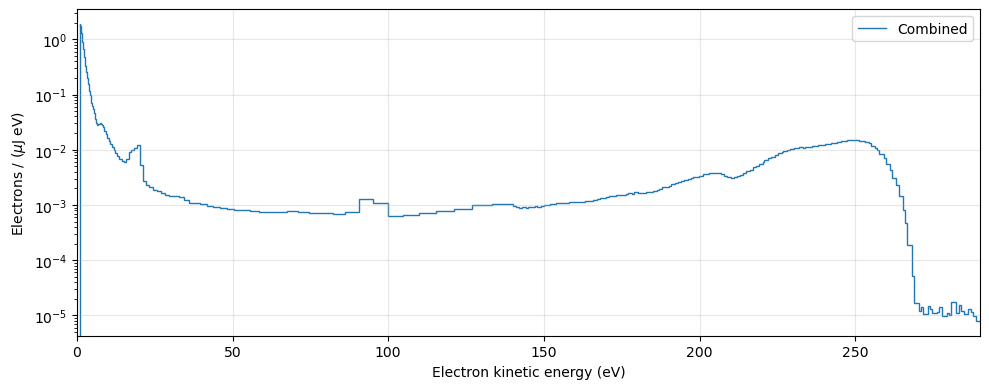

In [10]:
KE_LIM = (0, 290)
MQ_LIM = (0, 50)
MIN_REF_COUNTS = 100         # mask weak spectral bins in relative maps (reference interval)
REL_LIM = 0.10               # symmetric colour limits for relative maps

Y_e = divide(combined['e'], combined[exposure_key][:, None]) / dke
Y_i = divide(combined['i'], combined[exposure_key][:, None]) / dmq
ref_e = divide(combined['e'].sum(axis=0), combined[exposure_key].sum()) / dke
ref_i = divide(combined['i'].sum(axis=0), combined[exposure_key].sum()) / dmq

fig, ax = plt.subplots(figsize=(10, 4))
ax.stairs(ref_e, ke_edges, label='Combined')
ax.set(xlabel='Electron kinetic energy (eV)', ylabel=f'Electrons / ({unit} eV)', xlim=KE_LIM, yscale='log')
ax.legend()
fig.tight_layout()
ax.grid(alpha=0.3)
plt.show()

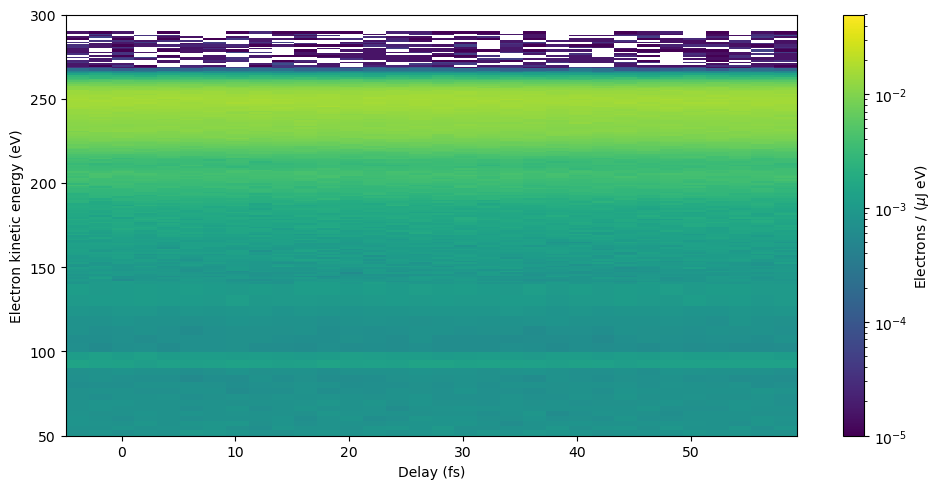

In [11]:
from matplotlib.colors import LogNorm

VMIN = 1e-5
VMAX = 5e-2

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.pcolormesh(delay_edges, ke_edges, Y_e.T,
                   shading='flat', cmap='viridis',
                   norm=LogNorm(vmin=VMIN, vmax=VMAX))

fig.colorbar(im, ax=ax, label=f'Electrons / ({unit} eV)')
ax.set(xlabel='Delay (fs)',
       ylabel='Electron kinetic energy (eV)',
       ylim=(50, 300))

fig.tight_layout()

plt.show()

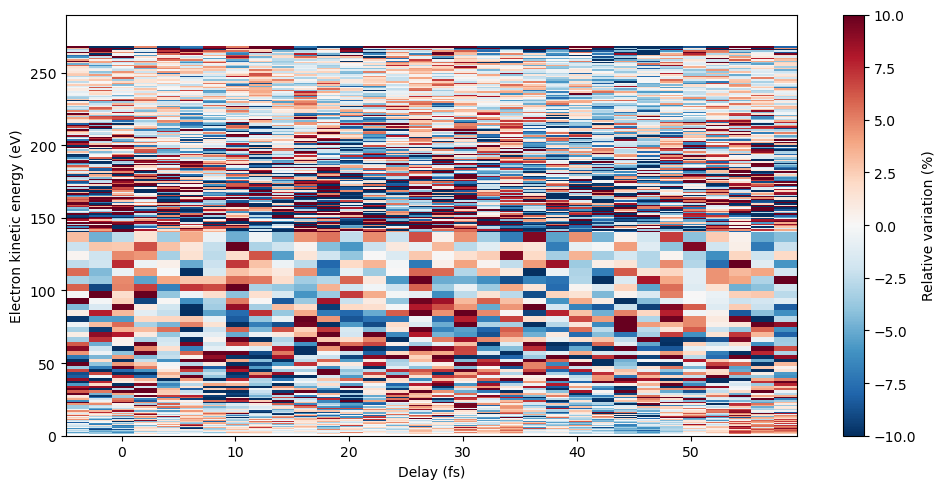

In [12]:
ref_e_delay = delay_reference(combined['e'],
                              combined[exposure_key]) / dke

R_e = divide(Y_e - ref_e_delay, ref_e_delay)
R_e[:, combined['e'][ref_mask].sum(axis=0) < MIN_REF_COUNTS] = np.nan

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.pcolormesh(delay_edges, ke_edges, 100 * R_e.T, shading='flat', cmap='RdBu_r',
                   vmin=-100 * REL_LIM, vmax=100 * REL_LIM)
fig.colorbar(im, ax=ax, label='Relative variation (%)')
ax.set(xlabel='Delay (fs)', ylabel='Electron kinetic energy (eV)', ylim=KE_LIM)
fig.tight_layout()
plt.show()

### Spectral shape

Normalise by the total electron count per delay to check changes in spectral shape. This removes overall yield changes and can introduce correlations between energy regions. The shape reference uses all delays.

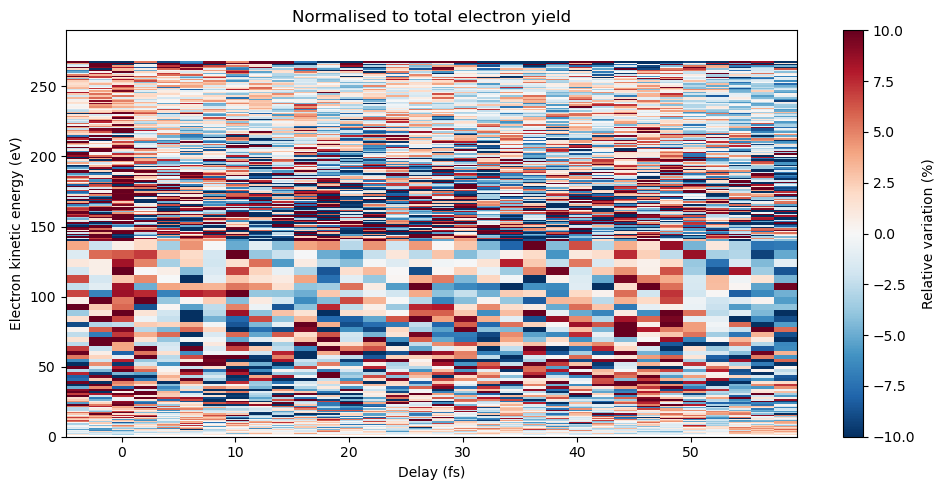

In [13]:
# Relative variation of the spectral shape
total_e = combined['e'].sum(axis=1)

Y_e_shape = divide(combined['e'], total_e[:, None]) / dke
ref_e_shape = divide(combined['e'].sum(axis=0),
                     total_e.sum()) / dke

R_e_shape = divide(Y_e_shape - ref_e_shape, ref_e_shape)
R_e_shape[:, combined['e'].sum(axis=0) < MIN_REF_COUNTS] = np.nan

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.pcolormesh(delay_edges, ke_edges, 100 * R_e_shape.T,
                   shading='flat', cmap='RdBu_r',
                   vmin=-100 * REL_LIM, vmax=100 * REL_LIM)

fig.colorbar(im, ax=ax, label='Relative variation (%)')
ax.set_title('Normalised to total electron yield')
ax.set(xlabel='Delay (fs)',
       ylabel='Electron kinetic energy (eV)',
       ylim=KE_LIM)

fig.tight_layout()
plt.show()

## 6. Ion spectra

Use the same normalisation and plot layout as for electrons. The relative maps show deviations from the mean, not pumped-minus-unpumped absorption.

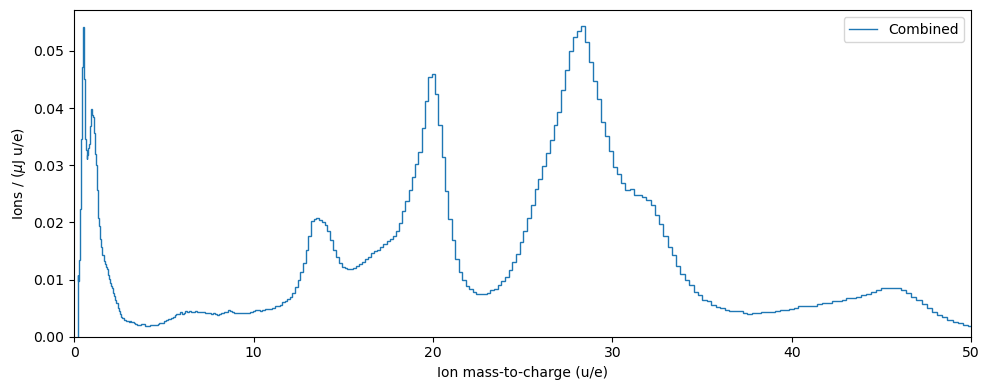

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.stairs(ref_i, mq_edges, label='Combined')
ax.set(xlabel='Ion mass-to-charge (u/e)', ylabel=f'Ions / ({unit} u/e)', xlim=MQ_LIM)
ax.legend()
fig.tight_layout()
plt.show()

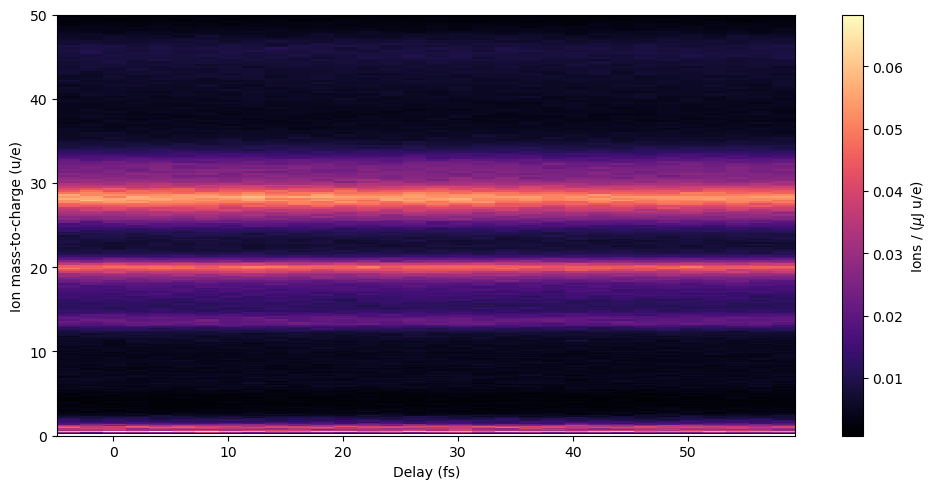

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.pcolormesh(delay_edges, mq_edges, Y_i.T, shading='flat', cmap='magma')
fig.colorbar(im, ax=ax, label=f'Ions / ({unit} u/e)')
ax.set(xlabel='Delay (fs)', ylabel='Ion mass-to-charge (u/e)', ylim=MQ_LIM)
fig.tight_layout()
plt.show()

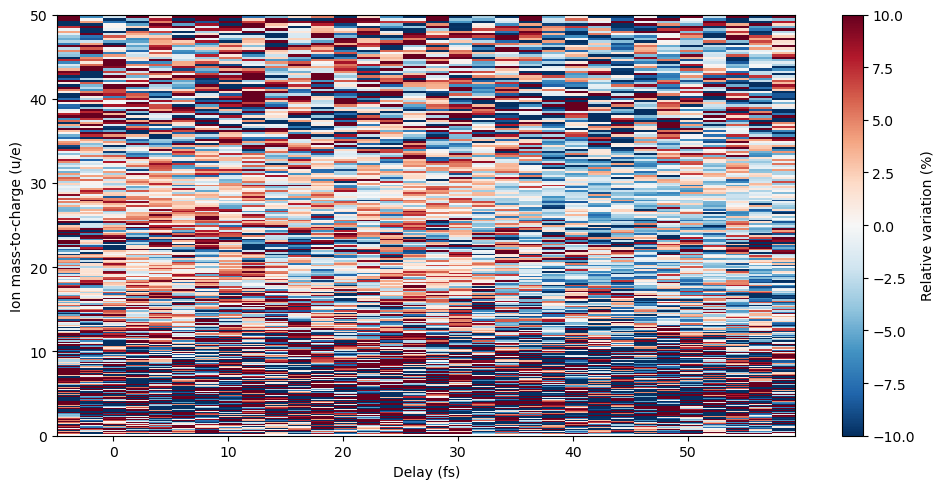

In [16]:
ref_i_delay = delay_reference(combined['i'],
                              combined[exposure_key]) / dmq

R_i = divide(Y_i - ref_i_delay, ref_i_delay)
R_i[:, combined['i'][ref_mask].sum(axis=0) < MIN_REF_COUNTS] = np.nan

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.pcolormesh(delay_edges, mq_edges, 100 * R_i.T, shading='flat', cmap='RdBu_r',
                   vmin=-100 * REL_LIM, vmax=100 * REL_LIM)
fig.colorbar(im, ax=ax, label='Relative variation (%)')
ax.set(xlabel='Delay (fs)', ylabel='Ion mass-to-charge (u/e)', ylim=MQ_LIM)
fig.tight_layout()
plt.show()

### TOF spectra

Inspect the uncorrected spectra in the detector coordinates as a calibration and background check.

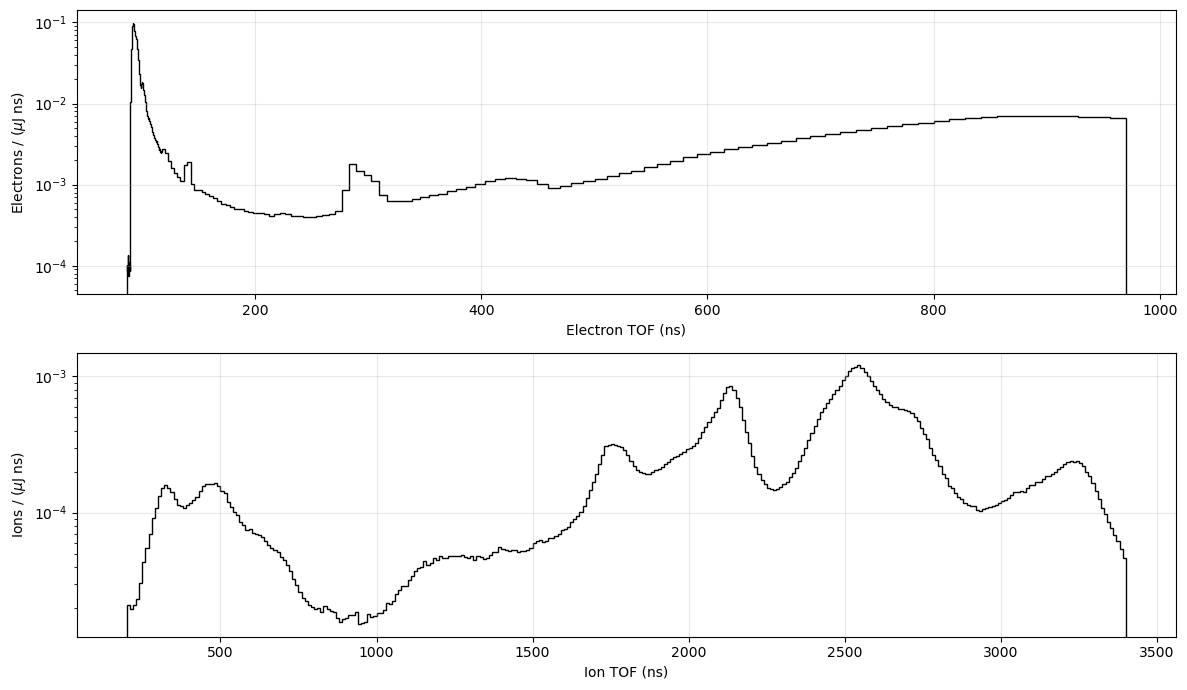

In [17]:
# Inspect the spectra in the original TOF coordinates.

etof_edges = axes['tof_edges'] / 10
itof_edges = axes['ion_tof_edges'] / 10

dtof_e = np.abs(np.diff(etof_edges))
dtof_i = np.diff(itof_edges)

fig, ax = plt.subplots(2, 1, figsize=(12, 7))

ax[0].stairs((ref_e * dke)[::-1] / dtof_e,
             etof_edges, color='k')

ax[1].stairs(ref_i * dmq / dtof_i,
             itof_edges, color='k')

ax[0].set(ylabel=f'Electrons / ({unit} ns)',
          xlabel='Electron TOF (ns)', yscale='log')

ax[1].set(ylabel=f'Ions / ({unit} ns)',
          xlabel='Ion TOF (ns)', yscale='log')

for a in ax:
    a.grid(alpha=0.3)

fig.tight_layout()
plt.show()

## 7. Temporal traces

Select the energy and mass windows after inspecting the spectra. Whole bins are selected by their centres; the actual edges are printed. The high-energy windows include direct photoelectrons; the hole assignments are tentative.

Approximate Poisson error bars treat exposure as fixed and do not include reference uncertainty, FEL fluctuations or detector systematics.

### 7.1 Electron yields

110–160 eV: actual edges 109.87–160.09 eV
210–220 eV: actual edges 209.91–220.26 eV
220–230 eV: actual edges 220.26–230.23 eV
230–240 eV: actual edges 230.23–240.29 eV
242–246 eV: actual edges 242.13–245.88 eV
246–250 eV: actual edges 245.88–249.72 eV
250–263 eV: actual edges 249.72–263.18 eV


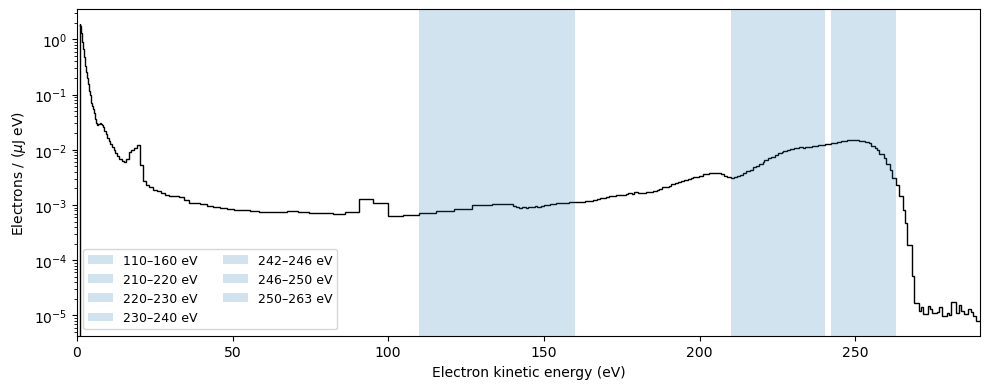

In [18]:
ENERGY_WINDOWS = [
    (110, 160),
    (210, 220),
    (220, 230),
    (230, 240),
    (242, 246),
    (246, 250),
    (250, 263),
]

RELATIVE_TRACES = True

windows = {}
for lo, hi in ENERGY_WINDOWS:
    mask = (ke >= lo) & (ke < hi)
    if not mask.any():
        raise ValueError(f'No electron bins in {lo}–{hi} eV')
    idx = np.flatnonzero(mask)
    windows[(lo, hi)] = mask
    print(f'{lo}–{hi} eV: actual edges {ke_edges[idx[0]]:.2f}–{ke_edges[idx[-1]+1]:.2f} eV')

# Check the energy windows against the integrated spectrum.
fig, ax = plt.subplots(figsize=(10, 4))
ax.stairs(ref_e, ke_edges, color='k')
for (lo, hi), mask in windows.items():
    idx = np.flatnonzero(mask)
    ax.axvspan(ke_edges[idx[0]], ke_edges[idx[-1]+1], alpha=0.2, label=f'{lo}–{hi} eV')
ax.set(xlabel='Electron kinetic energy (eV)', ylabel=f'Electrons / ({unit} eV)', xlim=KE_LIM, yscale='log')
ax.legend(ncol=2, fontsize=9)
fig.tight_layout()
plt.show()

110–160 eV: 123,812 electrons; median 3,811 / bin
210–220 eV: 111,883 electrons; median 3,439 / bin
220–230 eV: 218,401 electrons; median 6,782 / bin
230–240 eV: 302,638 electrons; median 9,271 / bin
242–246 eV: 136,089 electrons; median 4,240 / bin
246–250 eV: 152,363 electrons; median 4,673 / bin
250–263 eV: 359,605 electrons; median 11,096 / bin


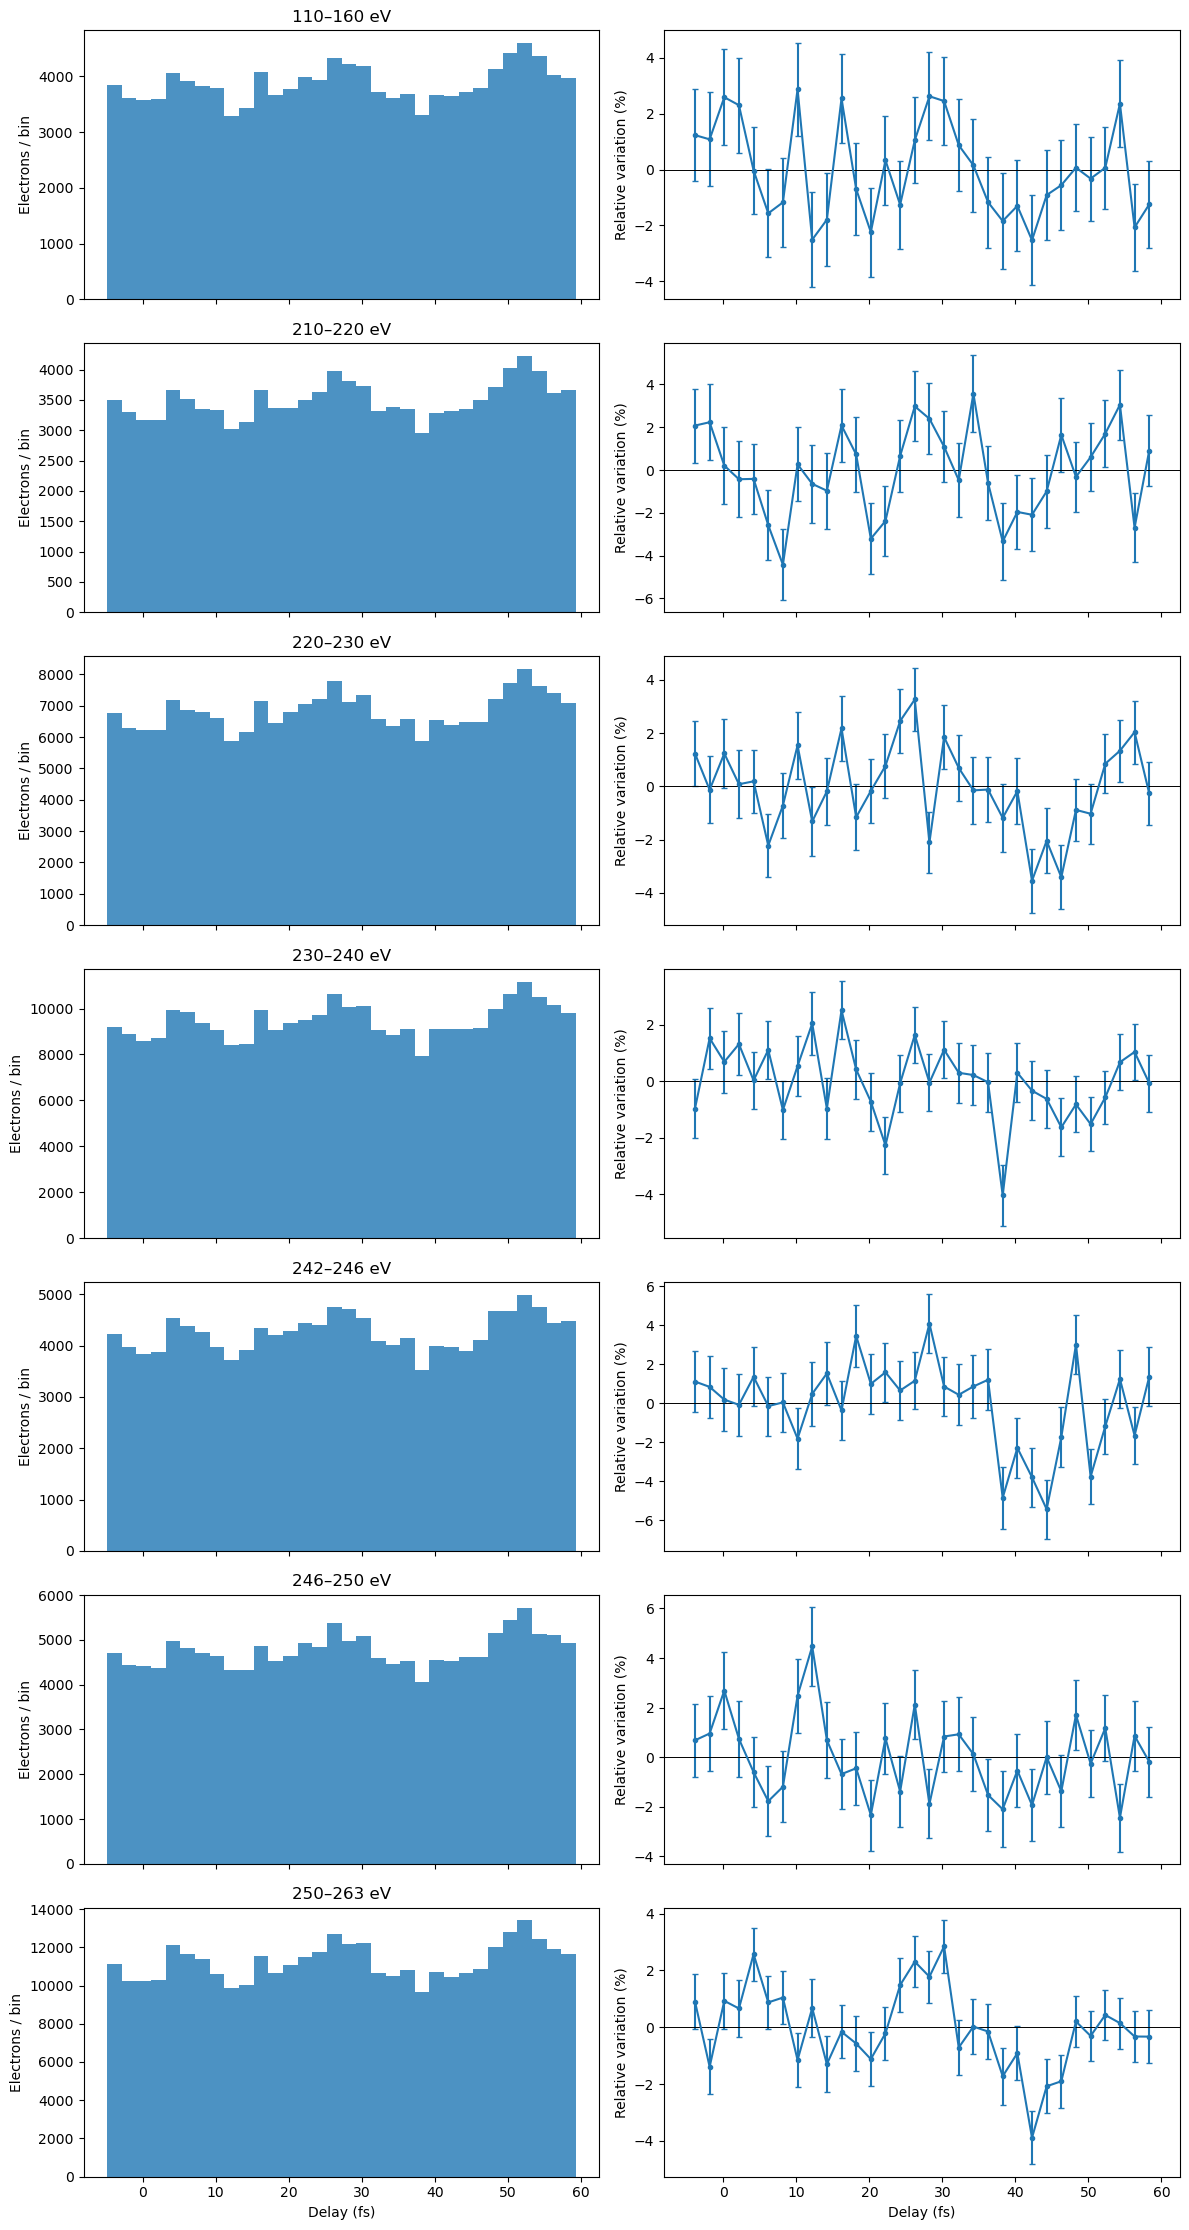

In [19]:
# Integrate counts (not counts/eV) in the selected windows.
def electron_trace(s, mask, relative=False):
    counts = s['e'][:, mask].sum(axis=1)
    exposure = s[exposure_key]

    y = divide(counts, exposure)
    err = divide(np.sqrt(counts), exposure)
    err[counts == 0] = np.nan

    if relative:
        ref = delay_reference(counts, exposure)
        y = 100 * (divide(y, ref) - 1)
        err = 100 * divide(err, ref)

    return counts, y, err

fig, ax = plt.subplots(len(windows), 2, figsize=(12, 3.2 * len(windows)),
                       sharex=True, squeeze=False)
for row, ((lo, hi), mask) in enumerate(windows.items()):
    counts, y, err = electron_trace(combined, mask, RELATIVE_TRACES)
    ax[row, 0].bar(delay, counts, width=np.diff(delay_edges), alpha=0.8)
    ax[row, 1].errorbar(delay, y, yerr=err, fmt='.-', capsize=2)
    if RELATIVE_TRACES:
        ax[row, 1].axhline(0, color='k', linewidth=0.7)
    ax[row, 0].set(ylabel='Electrons / bin', title=f'{lo}–{hi} eV')
    ax[row, 1].set_ylabel('Relative variation (%)' if RELATIVE_TRACES else f'Electrons / {unit}')
    print(f'{lo}–{hi} eV: {counts.sum():,.0f} electrons; median {np.median(counts):,.0f} / bin')

for a in ax[-1]:
    a.set_xlabel('Delay (fs)')
fig.tight_layout()
plt.show()

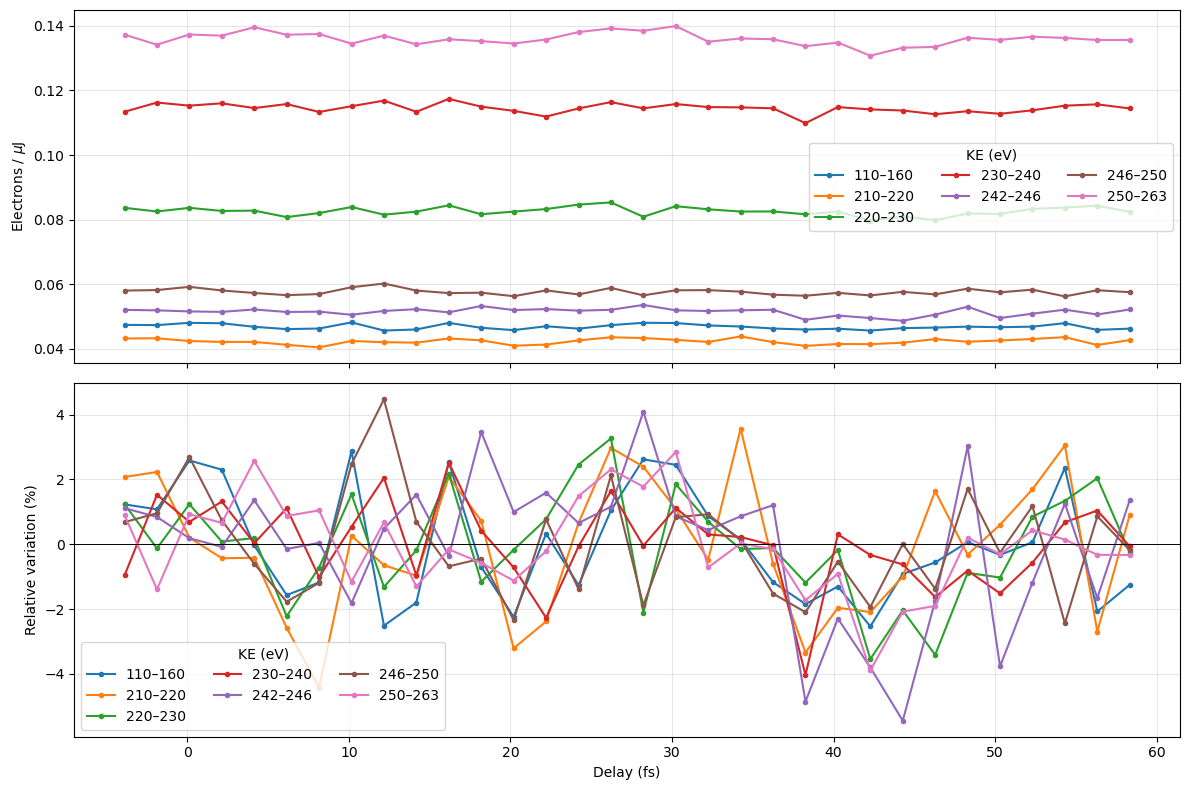

In [20]:
# Absolute and relative exposure-normalised electron yields.

fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for (lo, hi), mask in windows.items():

    counts = combined['e'][:, mask].sum(axis=1)
    exposure = combined[exposure_key]

    y = divide(counts, exposure)
    ref = delay_reference(counts, exposure)

    relative = 100 * (divide(y, ref) - 1)

    ax[0].plot(delay, y, '.-', label=f'{lo}–{hi}')
    ax[1].plot(delay, relative, '.-', label=f'{lo}–{hi}')

ax[0].set_ylabel(f'Electrons / {unit}')
ax[1].set_ylabel('Relative variation (%)')
ax[1].set_xlabel('Delay (fs)')
ax[1].axhline(0, color='k', linewidth=0.7)

for a in ax:
    a.legend(ncol=3, title='KE (eV)')
    a.grid(alpha=0.3)

fig.tight_layout()
plt.show()

### 7.2 Ion yields

0.5–1.5 u/e: actual edges 0.49–1.49
12–16 u/e: actual edges 12.01–16.05
19–21 u/e: actual edges 19.00–21.05
27–32 u/e: actual edges 26.94–31.89
44–47 u/e: actual edges 43.87–46.95


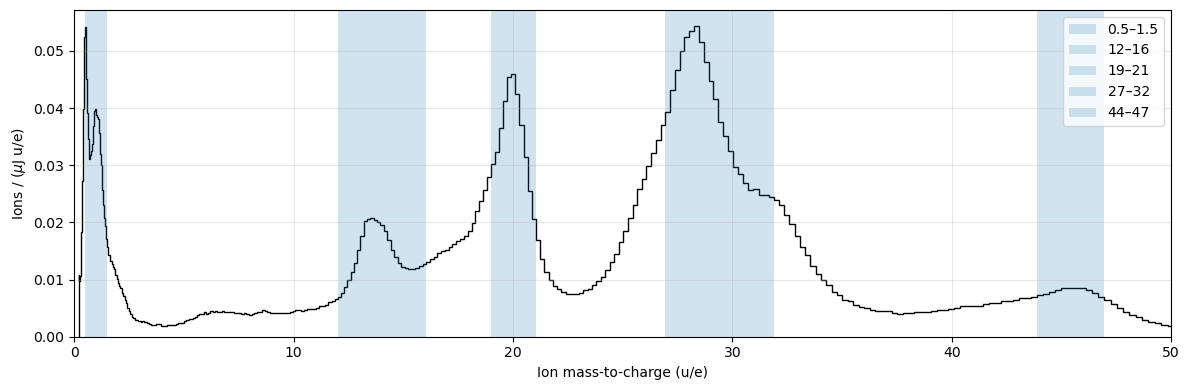

In [21]:
ION_YIELD_WINDOWS = [
    (0.5, 1.5),
    (12, 16),
    (19, 21),
    (27, 32),
    (44, 47)
]

ion_windows = {}

fig, ax = plt.subplots(figsize=(12, 4))
ax.stairs(ref_i, mq_edges, color='k')

for lo, hi in ION_YIELD_WINDOWS:

    mask = (mq >= lo) & (mq < hi)

    if not mask.any():
        raise ValueError(f'No ion bins in {lo}–{hi} u/e')

    ion_windows[(lo, hi)] = mask
    idx = np.flatnonzero(mask)

    print(f'{lo}–{hi} u/e: actual edges '
          f'{mq_edges[idx[0]]:.2f}–{mq_edges[idx[-1]+1]:.2f}')

    ax.axvspan(mq_edges[idx[0]], mq_edges[idx[-1]+1],
               alpha=0.2, label=f'{lo}–{hi}')

ax.set(xlabel='Ion mass-to-charge (u/e)',
       ylabel=f'Ions / ({unit} u/e)',
       xlim=MQ_LIM)

ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

0.5–1.5 u/e: 87,409 ions; median 2,723 / bin
12–16 u/e: 153,724 ions; median 4,742 / bin
19–21 u/e: 190,698 ions; median 5,918 / bin
27–32 u/e: 497,376 ions; median 15,400 / bin
44–47 u/e: 64,891 ions; median 2,010 / bin


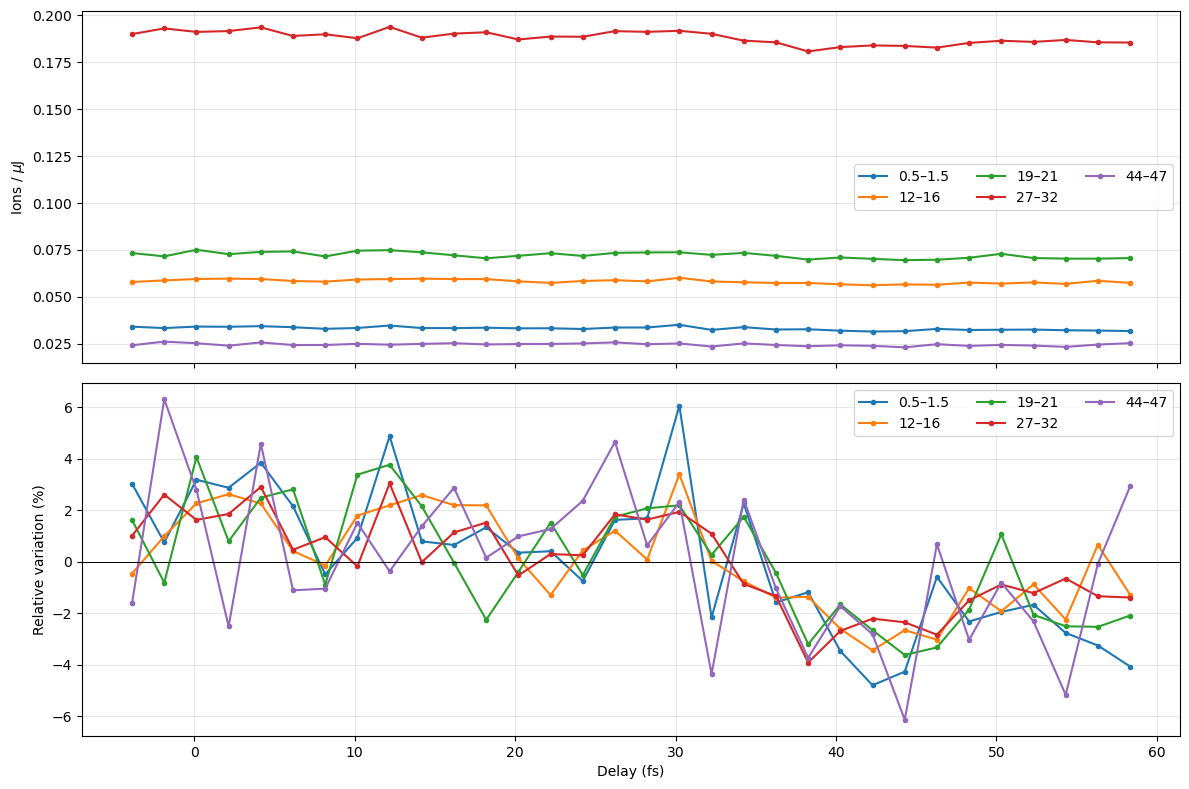

In [22]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for (lo, hi), mask in ion_windows.items():

    counts = combined['i'][:, mask].sum(axis=1)
    exposure = combined[exposure_key]

    y = divide(counts, exposure)
    ref = delay_reference(counts, exposure)

    relative = 100 * (divide(y, ref) - 1)

    ax[0].plot(delay, y, '.-', label=f'{lo}–{hi}')
    ax[1].plot(delay, relative, '.-', label=f'{lo}–{hi}')

    print(f'{lo}–{hi} u/e: {counts.sum():,.0f} ions; '
          f'median {np.median(counts):,.0f} / bin')

ax[0].set_ylabel(f'Ions / {unit}')
ax[1].set_ylabel('Relative variation (%)')
ax[1].set_xlabel('Delay (fs)')
ax[1].axhline(0, color='k', linewidth=0.7)

for a in ax:
    a.legend(ncol=3)
    a.grid(alpha=0.3)

fig.tight_layout()
plt.show()

### 7.3 GMD-bin comparison

Check the electron traces in different pulse-energy bins for one selected scan. This diagnostic deliberately uses all GMD bins in that file, independent of `GMD_BINS`, and always normalises per µJ.

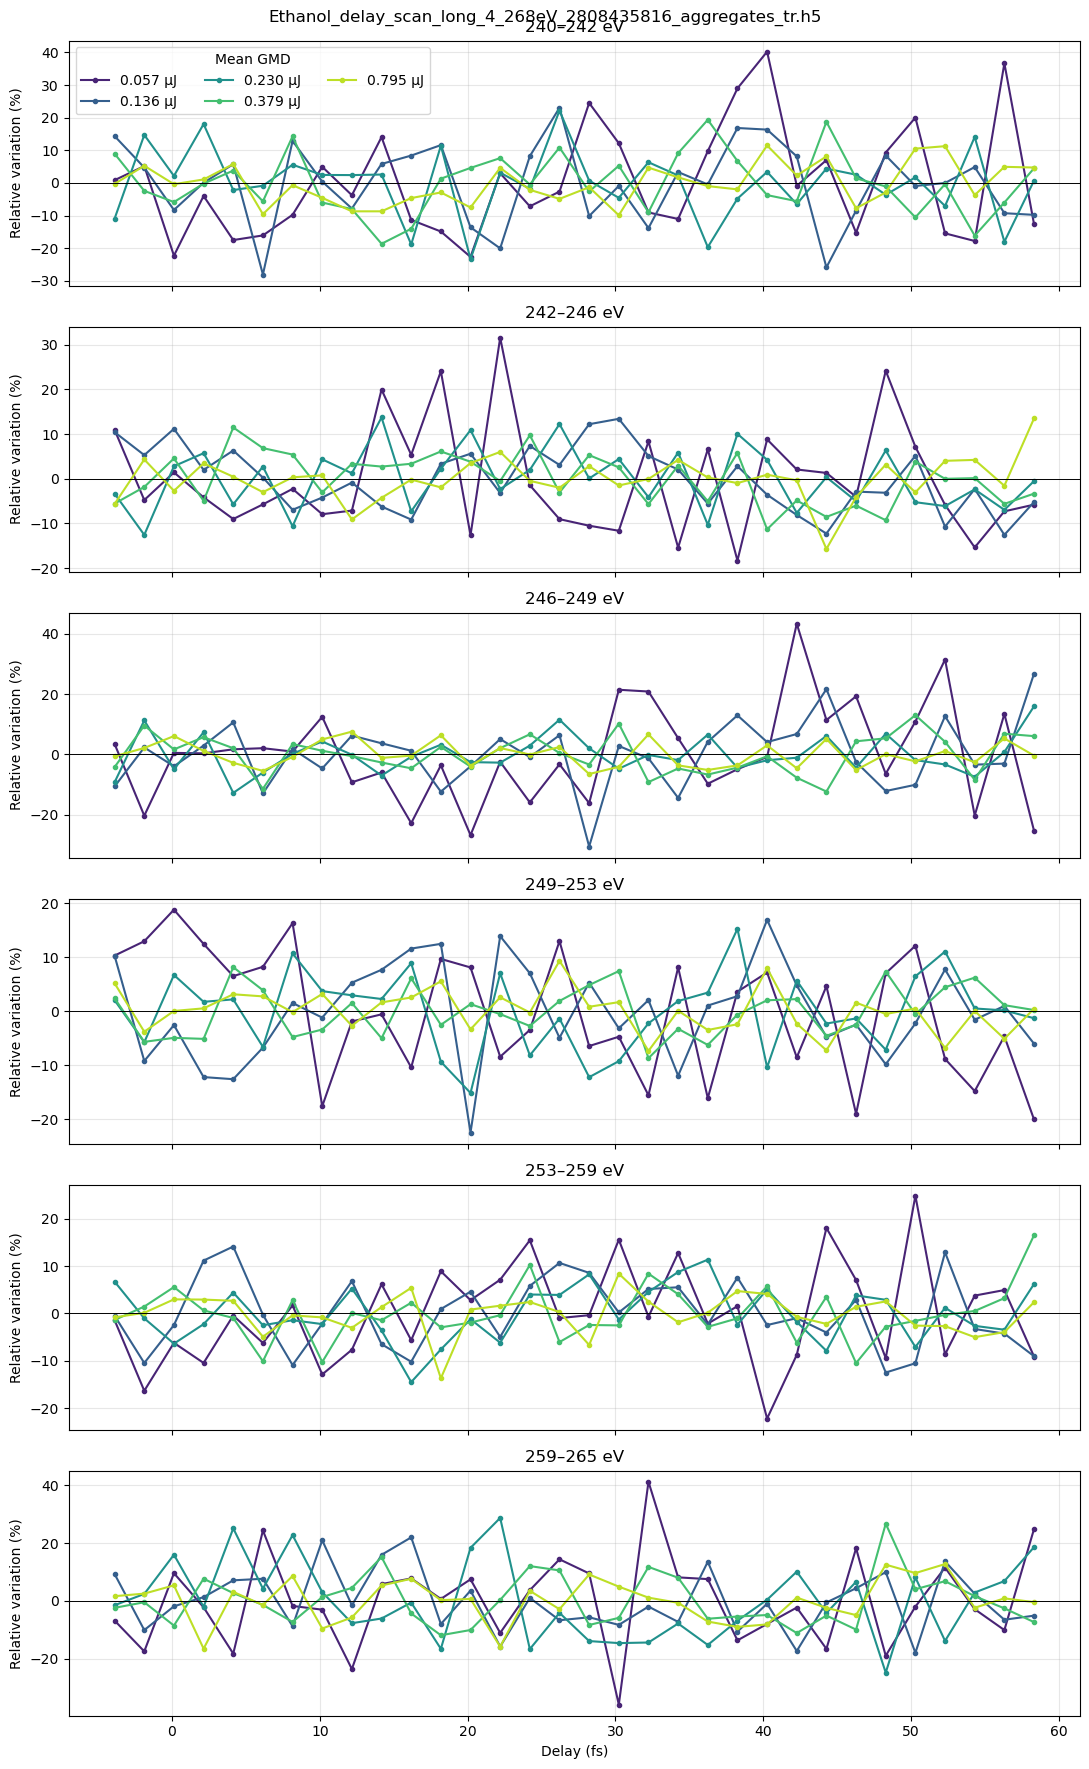

In [23]:
GMD_FILE = FILES[-1]

GMD_ENERGY_WINDOWS = [
    (240, 242),
    (242, 246),  # 5a photoelectron region
    (246, 249),  # 6a photoelectron region
    (249, 253),  # 7a region
    (253, 259),  # Outer valence
    (259, 265)
]


GMD_RELATIVE = True

with h5py.File(GMD_FILE, 'r') as f:
    n_gmd = f['n_per_bin'][:]
    D_gmd = f['D'][:]
    G_gmd = f['G'][:]
    gmd_edges = f['gmd_edges'][:]

# Convert means to counts and total pulse energy.
e_gmd = np.where(n_gmd[..., None] > 0, D_gmd, 0) * n_gmd[..., None]
g_gmd = np.where(n_gmd > 0, G_gmd, 0) * n_gmd

# Reverse electron TOF to increasing kinetic energy.
e_gmd = e_gmd[..., ::-1]

if DELAY_SIGN == -1:
    e_gmd = e_gmd[:, ::-1]
    g_gmd = g_gmd[:, ::-1]
    n_gmd = n_gmd[:, ::-1]

colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(gmd_edges)-1))

fig, ax = plt.subplots(len(GMD_ENERGY_WINDOWS), 1,
                       figsize=(11, 3 * len(GMD_ENERGY_WINDOWS)),
                       sharex=True, squeeze=False)

for a, (lo, hi) in zip(ax[:, 0], GMD_ENERGY_WINDOWS):

    mask = (ke >= lo) & (ke < hi)

    if not mask.any():
        raise ValueError(f'No electron bins in {lo}–{hi} eV')

    for j, color in enumerate(colors):

        counts = e_gmd[j][:, mask].sum(axis=1)
        y = divide(counts, g_gmd[j])

        mean_gmd = divide(g_gmd[j].sum(), n_gmd[j].sum())

        if GMD_RELATIVE:
            ref = delay_reference(counts, g_gmd[j])
            y = 100 * (divide(y, ref) - 1)

        a.plot(delay, y, '.-', color=color,
               label=f'{mean_gmd:.3f} µJ')

    a.set_title(f'{lo}–{hi} eV')
    a.set_ylabel('Relative variation (%)' if GMD_RELATIVE
                 else 'Electrons / µJ')

    if GMD_RELATIVE:
        a.axhline(0, color='k', linewidth=0.7)

    a.grid(alpha=0.3)

ax[0, 0].legend(ncol=3, title='Mean GMD')
ax[-1, 0].set_xlabel('Delay (fs)')

fig.suptitle(Path(GMD_FILE).name)
fig.tight_layout()
plt.show()

## 8. Comparison between scans

Compare absolute, exposure-normalised traces rather than centring each individual scan independently; otherwise run-to-run offsets could disappear. The pooled trace is weighted by exposure.

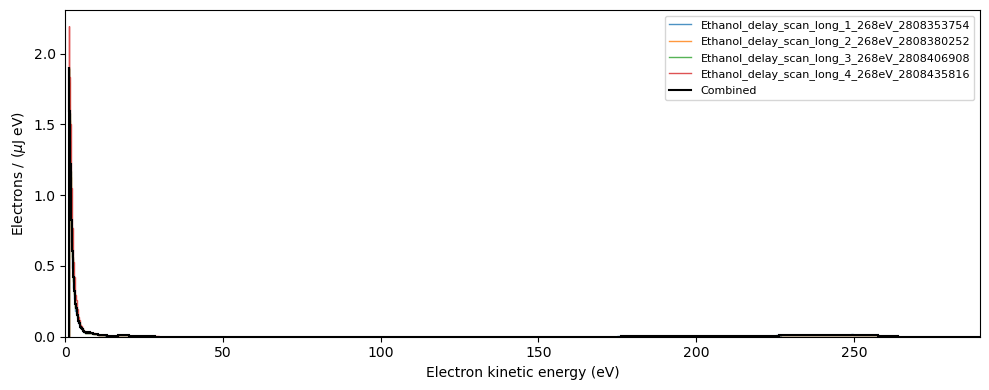

In [24]:
fig, ax = plt.subplots(figsize=(10, 4))
for name, s in scans.items():
    spectrum = divide(s['e'].sum(axis=0), s[exposure_key].sum()) / dke
    ax.stairs(spectrum, ke_edges, label=name.replace('_aggregates_tr.h5', ''), alpha=0.8)
ax.stairs(ref_e, ke_edges, color='k', linewidth=1.5, label='Combined')
ax.set(xlabel='Electron kinetic energy (eV)', ylabel=f'Electrons / ({unit} eV)', xlim=KE_LIM)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

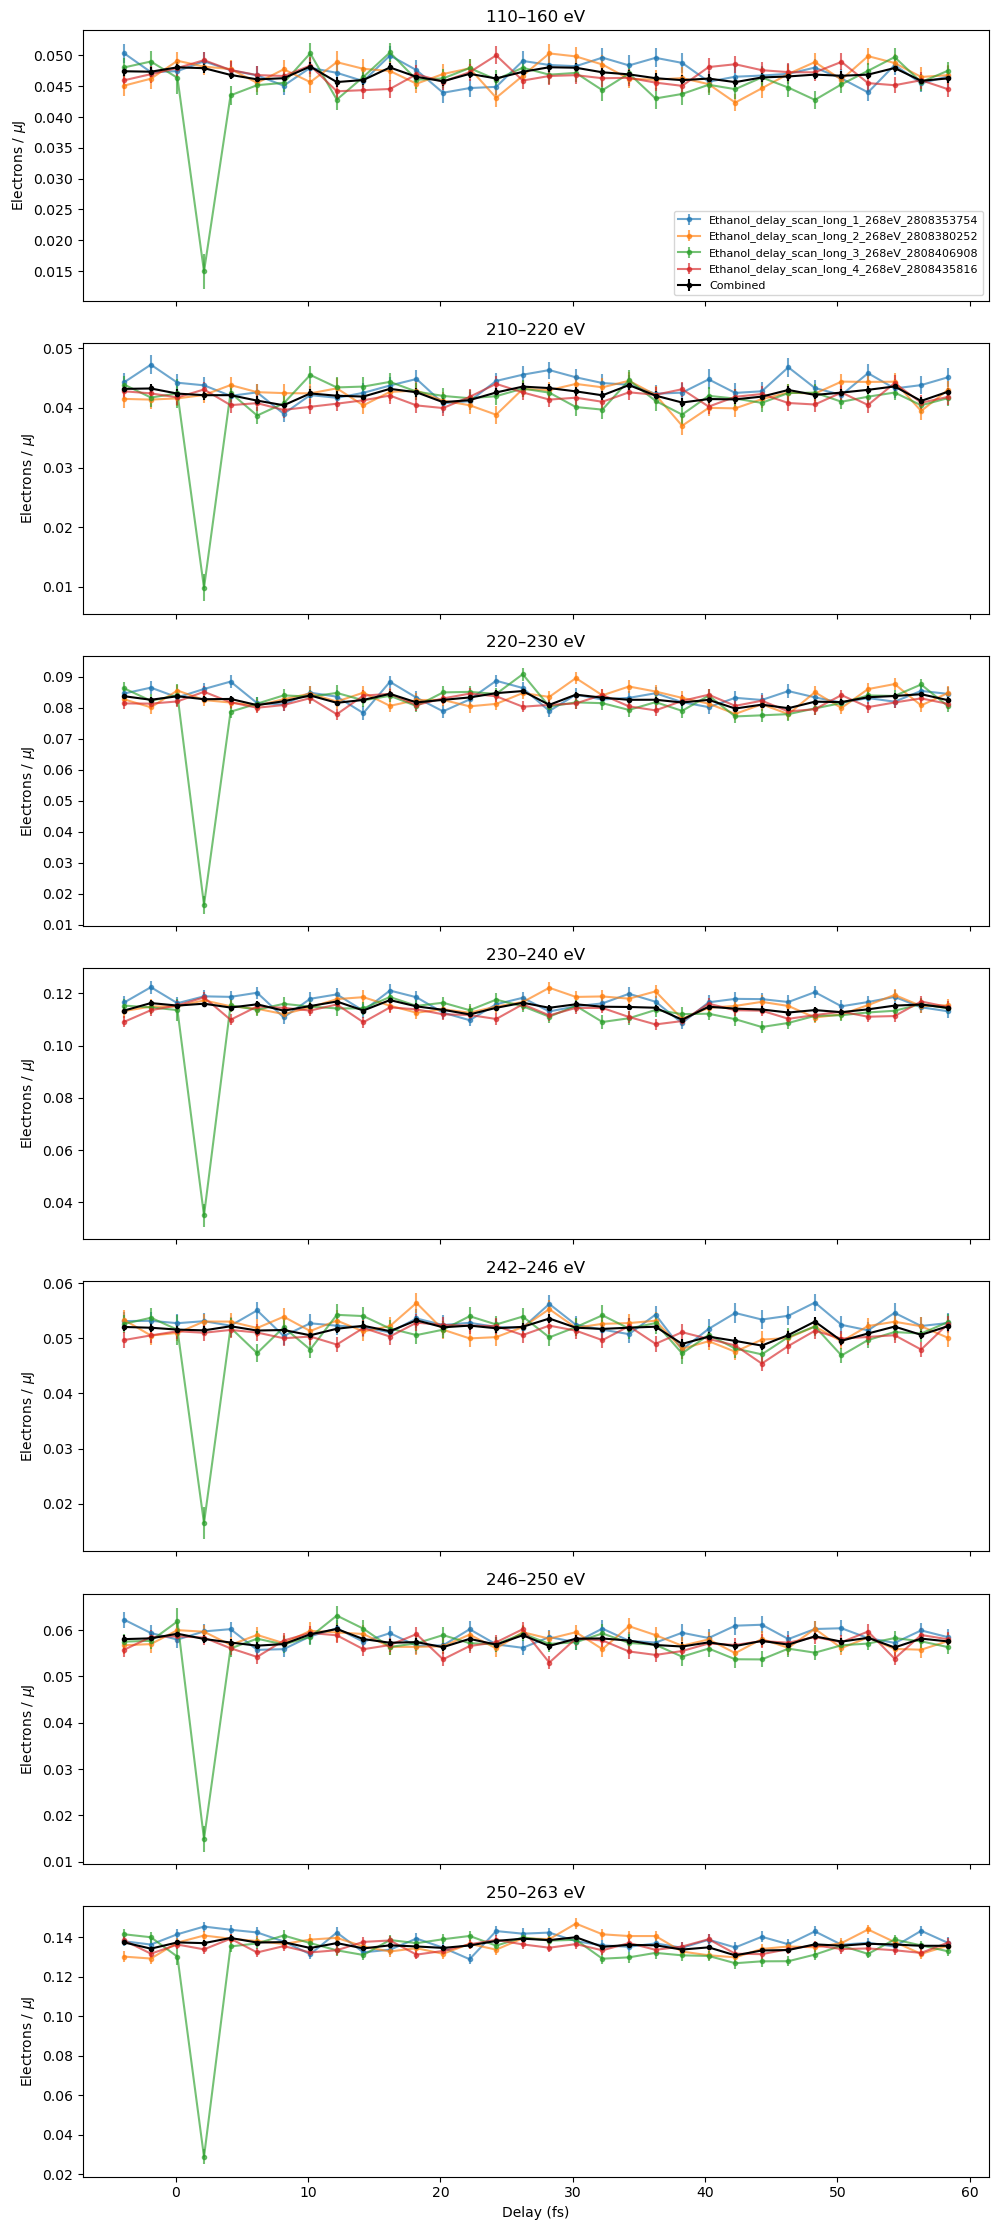

In [25]:
fig, ax = plt.subplots(len(windows), 1, figsize=(10, 3.2 * len(windows)),
                       sharex=True, squeeze=False)
for a, ((lo, hi), mask) in zip(ax[:, 0], windows.items()):
    for name, s in scans.items():
        _, y, err = electron_trace(s, mask)
        a.errorbar(delay, y, yerr=err, fmt='.-', alpha=0.65,
                   label=name.replace('_aggregates_tr.h5', ''))
    _, y, err = electron_trace(combined, mask)
    a.errorbar(delay, y, yerr=err, fmt='k.-', linewidth=1.5, label='Combined')
    a.set(title=f'{lo}–{hi} eV', ylabel=f'Electrons / {unit}')
ax[0, 0].legend(fontsize=8)
ax[-1, 0].set_xlabel('Delay (fs)')
fig.tight_layout()
plt.show()

## 9. Covariance

Compare total covariance, covariance calculated within GMD bins, and partial covariance with the linear GMD contribution removed. Moments are pooled with shot weights at each delay, using only GMD-delay cells meeting the minimum shot count and positive finite GMD variance. These are covariance observables, not true coincidences.

The electron–electron maps and gates exclude pairs near the TOF diagonal. The dead-time cut is a detector diagnostic, not a correction for missing pairs. No temporal smoothing or fit is applied. The approximate standard-error maps are diagnostic scales, not significance tests.

### 9.1 Calculate time-resolved covariance

In [26]:
# ---- Time-resolved covariance -----------------------------------------------

COV_FILES = FILES
# COV_FILES = FILES[-1:]       # Latest scan only
# COV_FILES = FILES[:3] + FILES[4:]  # Exclude scan 4 as a diagnostic

COV_GMD_BINS = GMD_BINS

REBIN_E = 1
REBIN_I = 2

MIN_COV_SHOTS = 300
CLIP_PCT = 99.5
Z_MAX = 6

WINDOW_EST = 'partial on GMD'
DEAD_TIME_NS = 2.0


# Merge neighbouring bins, retaining the final group.
def rebin_edges(edges, factor):
    return np.r_[edges[:-1:factor], edges[-1]]


cov_ke_edges = rebin_edges(ke_edges, REBIN_E)
cov_mq_edges = rebin_edges(mq_edges, REBIN_I)

cov_ke = (cov_ke_edges[1:] + cov_ke_edges[:-1]) / 2
cov_mq = (cov_mq_edges[1:] + cov_mq_edges[:-1]) / 2

cov_dke = np.diff(cov_ke_edges)
cov_dmq = np.diff(cov_mq_edges)

ne, ni, nz = len(cov_ke), len(cov_mq), len(delay)

idx_e = np.arange(0, len(ke_edges)-1, REBIN_E)
idx_i = np.arange(0, len(mq_edges)-1, REBIN_I)


def rebin_vector(x, idx):
    return np.add.reduceat(x, idx)


def rebin_matrix(x, idx1, idx2):
    x = np.add.reduceat(x, idx1, axis=0)
    return np.add.reduceat(x, idx2, axis=1)


# Covariance estimates: delay is the first axis.
print(f'Matrix storage estimate: {3 * nz * (ne*ne + ni*ni + ne*ni) * 8 / 1e6:.1f} MB')
EST = {
    name: {
        'DD': np.zeros((nz, ne, ne)),
        'CC': np.zeros((nz, ni, ni)),
        'DC': np.zeros((nz, ne, ni))
    }
    for name in ['total', 'within GMD bins', 'partial on GMD']
}

n_cov = np.zeros(nz)
g_cov = np.zeros(nz)

D_sum = np.zeros((nz, ne))
C_sum = np.zeros((nz, ni))


for path in COV_FILES:

    with h5py.File(path, 'r') as f:

        if any(not np.array_equal(f[key][:], axes[key])
               for key in axes):
            raise ValueError(f'{Path(path).name}: incompatible bin edges')

        n = f['n_per_bin'][:]

        bins = (range(n.shape[0]) if COV_GMD_BINS is None
                else COV_GMD_BINS)

        n_used = 0

        for j in bins:
            for k in range(nz):

                N = n[j, k]

                if N < MIN_COV_SHOTS:
                    continue

                G = f['G'][j, k]
                GG = f['GtG'][j, k]
                vG = GG - G**2

                if not np.isfinite(vG) or vG <= 0:
                    continue

                # Index on the calibrated, increasing delay axis.
                iz = k if DELAY_SIGN == 1 else nz - 1 - k

                # First moments, in increasing KE and m/q.
                D = rebin_vector(f['D'][j, k][::-1], idx_e)
                C = rebin_vector(f['C'][j, k], idx_i)

                # Second moments.
                DD = rebin_matrix(f['DtD'][j, k][::-1, ::-1],
                                  idx_e, idx_e)
                CC = rebin_matrix(f['CtC'][j, k],
                                  idx_i, idx_i)
                DC = rebin_matrix(f['DtC'][j, k][::-1, :],
                                  idx_e, idx_i)

                DG = rebin_vector(f['DtG'][j, k][::-1], idx_e)
                CG = rebin_vector(f['CtG'][j, k], idx_i)

                # Covariance within each GMD-delay cell.
                cDD = DD - np.outer(D, D)
                cCC = CC - np.outer(C, C)
                cDC = DC - np.outer(D, C)

                cDG = DG - D * G
                cCG = CG - C * G

                # Partial covariance on GMD.
                pDD = cDD - np.outer(cDG, cDG) / vG
                pCC = cCC - np.outer(cCG, cCG) / vG
                pDC = cDC - np.outer(cDG, cCG) / vG

                # Accumulate moments and covariance weighted by shots.
                D_sum[iz] += N * D
                C_sum[iz] += N * C

                for key, M in zip(['DD', 'CC', 'DC'], [DD, CC, DC]):
                    EST['total'][key][iz] += N * M

                for key, M in zip(['DD', 'CC', 'DC'], [cDD, cCC, cDC]):
                    EST['within GMD bins'][key][iz] += N * M

                for key, M in zip(['DD', 'CC', 'DC'], [pDD, pCC, pDC]):
                    EST['partial on GMD'][key][iz] += N * M

                n_cov[iz] += N
                g_cov[iz] += N * G
                n_used += N

    print(f'{Path(path).name}: {n_used:,.0f} shots used')


# Convert accumulated sums back to means.
mD_cov = divide(D_sum, n_cov[:, None])
mC_cov = divide(C_sum, n_cov[:, None])
mean_G_cov = divide(g_cov, n_cov)

for name, E in EST.items():
    for key in ['DD', 'CC', 'DC']:
        np.divide(E[key], n_cov[:, None, None],
                  out=E[key],
                  where=n_cov[:, None, None] > 0)

        E[key][n_cov == 0] = np.nan


# Total covariance: subtract products of the pooled first moments.
for k in range(nz):
    EST['total']['DD'][k] -= np.outer(mD_cov[k], mD_cov[k])
    EST['total']['CC'][k] -= np.outer(mC_cov[k], mC_cov[k])
    EST['total']['DC'][k] -= np.outer(mD_cov[k], mC_cov[k])


# Mask electron pairs by the separation of their TOF bin centres.

cov_tof = calibration.tof_of_ke(cov_ke)

delta_tof = np.abs(cov_tof[:, None] - cov_tof[None, :])

band = delta_tof <= DEAD_TIME_NS

print(f'\nTotal shots used: {n_cov.sum():,.0f}')
print(f'Electron bins: {ne}; ion bins: {ni}; delay bins: {nz}')
print(f'Median shots per delay: {np.median(n_cov):,.0f}')

print(f'Matrix storage: '
      f'{sum(M.nbytes for E in EST.values() for M in E.values()) / 1e6:.1f} MB')

Matrix storage estimate: 99.4 MB
Ethanol_delay_scan_long_1_268eV_2808353754_aggregates_tr.h5: 2,414,666 shots used
Ethanol_delay_scan_long_2_268eV_2808380252_aggregates_tr.h5: 2,407,157 shots used
Ethanol_delay_scan_long_3_268eV_2808406908_aggregates_tr.h5: 2,330,025 shots used
Ethanol_delay_scan_long_4_268eV_2808435816_aggregates_tr.h5: 2,439,601 shots used

Total shots used: 9,591,449
Electron bins: 252; ion bins: 160; delay bins: 32
Median shots per delay: 301,738
Matrix storage: 99.4 MB


### 9.2 Electron pair detection

Observed pair moments relative to the independent-electron expectation within each GMD-delay cell. Used to inspect the dead-time region.

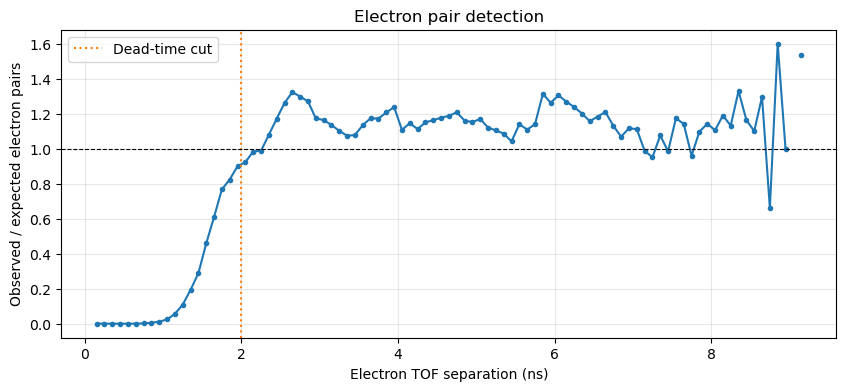

In [27]:
# ---- Electron pair detection vs TOF separation -----------------------------

DT_STEP = 0.1       # ns
DT_MAX = 10        # ns
DEAD_TIME_KE = (210, 265)

dt_edges = np.arange(0, DT_MAX + DT_STEP, DT_STEP)
dt = (dt_edges[:-1] + dt_edges[1:]) / 2

observed = np.zeros(len(dt))
expected = np.zeros(len(dt))

tof = calibration.tof_of_ke(cov_ke)

delta_tof = np.abs(tof[:, None] - tof[None, :])

gate = ((cov_ke >= DEAD_TIME_KE[0]) &
        (cov_ke < DEAD_TIME_KE[1]))

# Use each electron pair once and exclude the diagonal.
pair_mask = (gate[:, None] & gate[None, :] &
             np.triu(np.ones((ne, ne), dtype=bool), k=1))

for path in COV_FILES:

    with h5py.File(path, 'r') as f:

        n = f['n_per_bin'][:]

        bins = (range(n.shape[0]) if COV_GMD_BINS is None
                else COV_GMD_BINS)

        for j in bins:
            for k in range(n.shape[1]):

                N = n[j, k]

                if N < MIN_COV_SHOTS:
                    continue

                D = rebin_vector(f['D'][j, k][::-1], idx_e)

                DD = rebin_matrix(
                    f['DtD'][j, k][::-1, ::-1], idx_e, idx_e)

                independent = np.outer(D, D)

                observed += np.histogram(
                    delta_tof[pair_mask],
                    bins=dt_edges,
                    weights=N * DD[pair_mask])[0]

                expected += np.histogram(
                    delta_tof[pair_mask],
                    bins=dt_edges,
                    weights=N * independent[pair_mask])[0]

ratio = divide(observed, expected)

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(dt, ratio, '.-')
ax.axvline(DEAD_TIME_NS, color='C1', ls=':', label='Dead-time cut')
ax.legend()
ax.axhline(1, color='k', ls='--', lw=0.8)

ax.set(xlabel='Electron TOF separation (ns)',
       ylabel='Observed / expected electron pairs',
       title='Electron pair detection')

ax.grid(alpha=0.3)

plt.show()

### 9.3 Delay-integrated electron–electron covariance

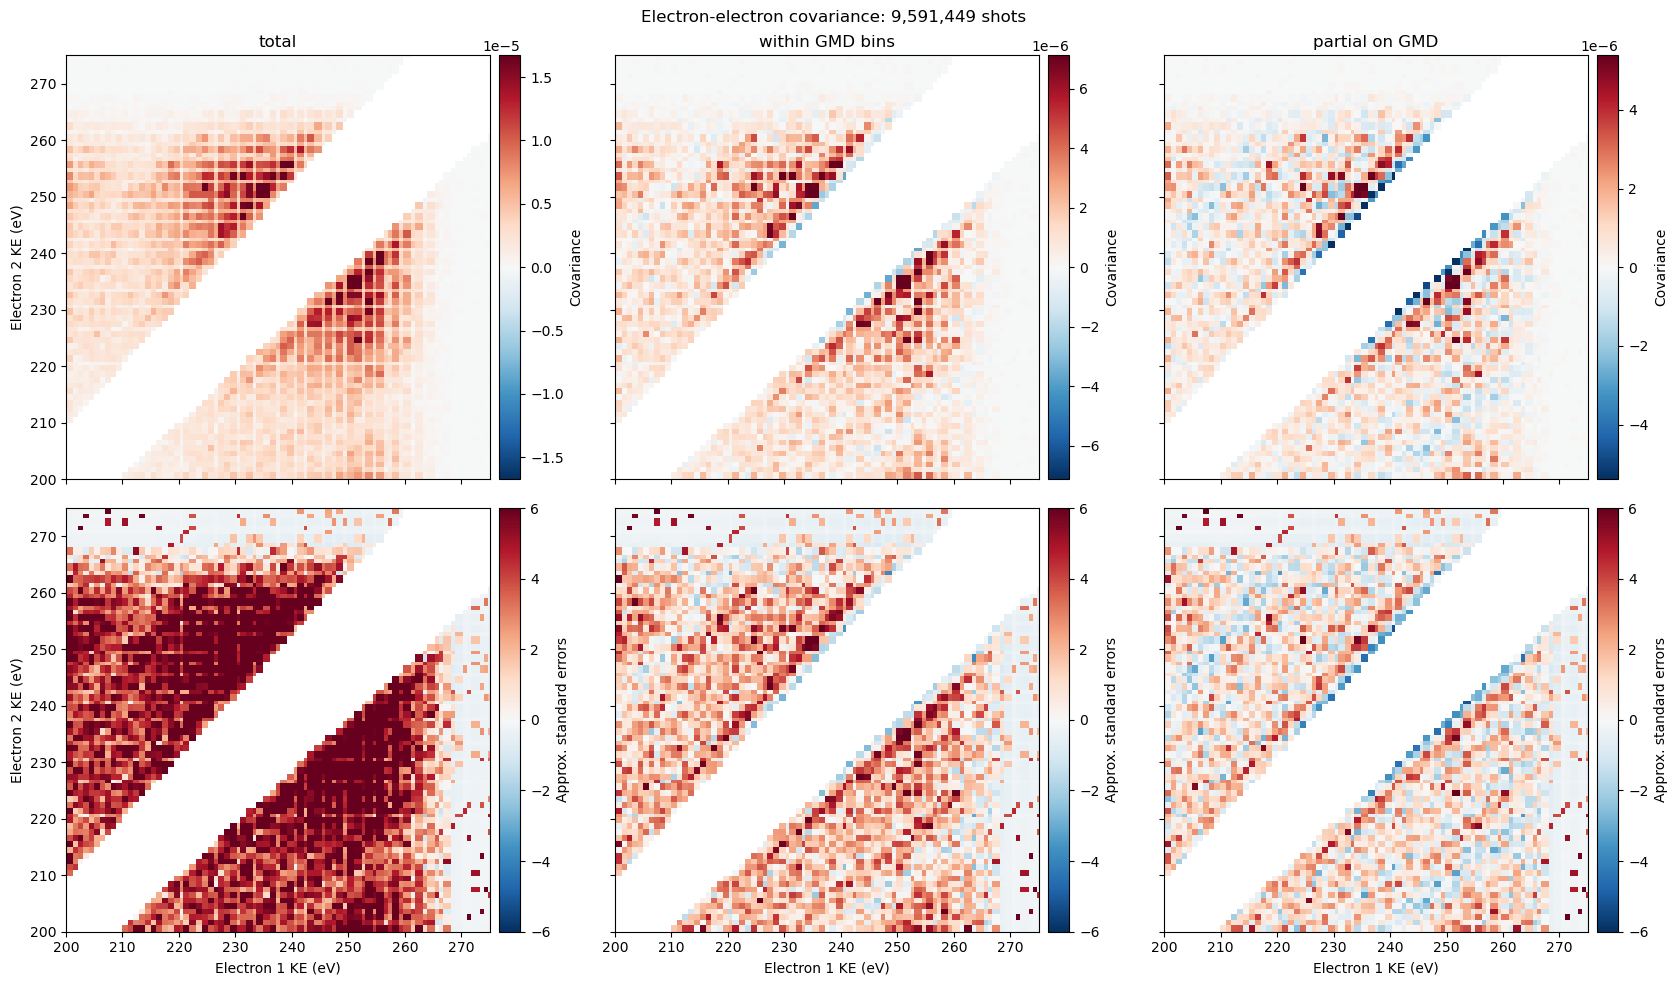

In [28]:
# ---- Delay-integrated electron-electron covariance ---------------------------

COV_DELAY_WINDOW = None
# COV_DELAY_WINDOW = (-5, 5)   # fs

COV_KE_LIM = (200, 275)
COV_MQ_LIM = (0, 50)

if COV_DELAY_WINDOW is None:
    cov_delay_mask = n_cov > 0
else:
    lo, hi = COV_DELAY_WINDOW
    cov_delay_mask = (delay >= lo) & (delay < hi) & (n_cov > 0)

N = n_cov[cov_delay_mask].sum()

if N == 0:
    raise ValueError('No shots in the selected delay window')

w = n_cov[cov_delay_mask] / N

# Shot-weighted covariance over the selected delays.
EST_AV = {
    name: {
        key: np.tensordot(w, M[cov_delay_mask], axes=1)
        for key, M in E.items()
    }
    for name, E in EST.items()
}


# Same approximate standard errors as in the static notebook.
for E in EST_AV.values():

    vd = np.clip(np.diag(E['DD']), 0, None)
    vc = np.clip(np.diag(E['CC']), 0, None)

    E['se_DD'] = np.sqrt(np.outer(vd, vd) / N)
    E['se_DC'] = np.sqrt(np.outer(vd, vc) / N)

    for key in ['se_DD', 'se_DC']:
        E[key][E[key] == 0] = np.nan


def show_cov_map(ax, M, x_edges, y_edges, vmax=None, label=None):

    if vmax is None:
        vmax = np.nanpercentile(np.abs(M), CLIP_PCT)
        if not np.isfinite(vmax) or vmax == 0:
            vmax = 1.0

    im = ax.pcolormesh(x_edges, y_edges, M,
                       cmap='RdBu_r', shading='flat',
                       vmin=-vmax, vmax=vmax)

    plt.colorbar(im, ax=ax, label=label,
                 fraction=0.046, pad=0.02)

    return im


fig, ax = plt.subplots(2, 3, figsize=(17, 10),
                       sharex=True, sharey=True)

# Determine the colour scale within the plotted energy range.
inside = (cov_ke >= COV_KE_LIM[0]) & (cov_ke <= COV_KE_LIM[1])

for k, (name, E) in enumerate(EST_AV.items()):

    M = np.where(band, np.nan, E['DD'])

    vmax = np.nanpercentile(np.abs(M[np.ix_(inside, inside)]),
                            CLIP_PCT)

    if not np.isfinite(vmax) or vmax == 0:
        vmax = 1.0

    show_cov_map(ax[0, k], M, cov_ke_edges, cov_ke_edges,
                 vmax=vmax, label='Covariance')

    show_cov_map(ax[1, k], M / E['se_DD'],
                 cov_ke_edges, cov_ke_edges,
                 vmax=Z_MAX, label='Approx. standard errors')

    ax[0, k].set_title(name)
    ax[1, k].set_xlabel('Electron 1 KE (eV)')

for a in ax[:, 0]:
    a.set_ylabel('Electron 2 KE (eV)')

for a in ax.flat:
    a.set(xlim=COV_KE_LIM, ylim=COV_KE_LIM)
    a.set_aspect('equal')

fig.suptitle(f'Electron-electron covariance: {N:,.0f} shots')
fig.tight_layout()
plt.show()

### 9.4 Delay-integrated electron–ion covariance

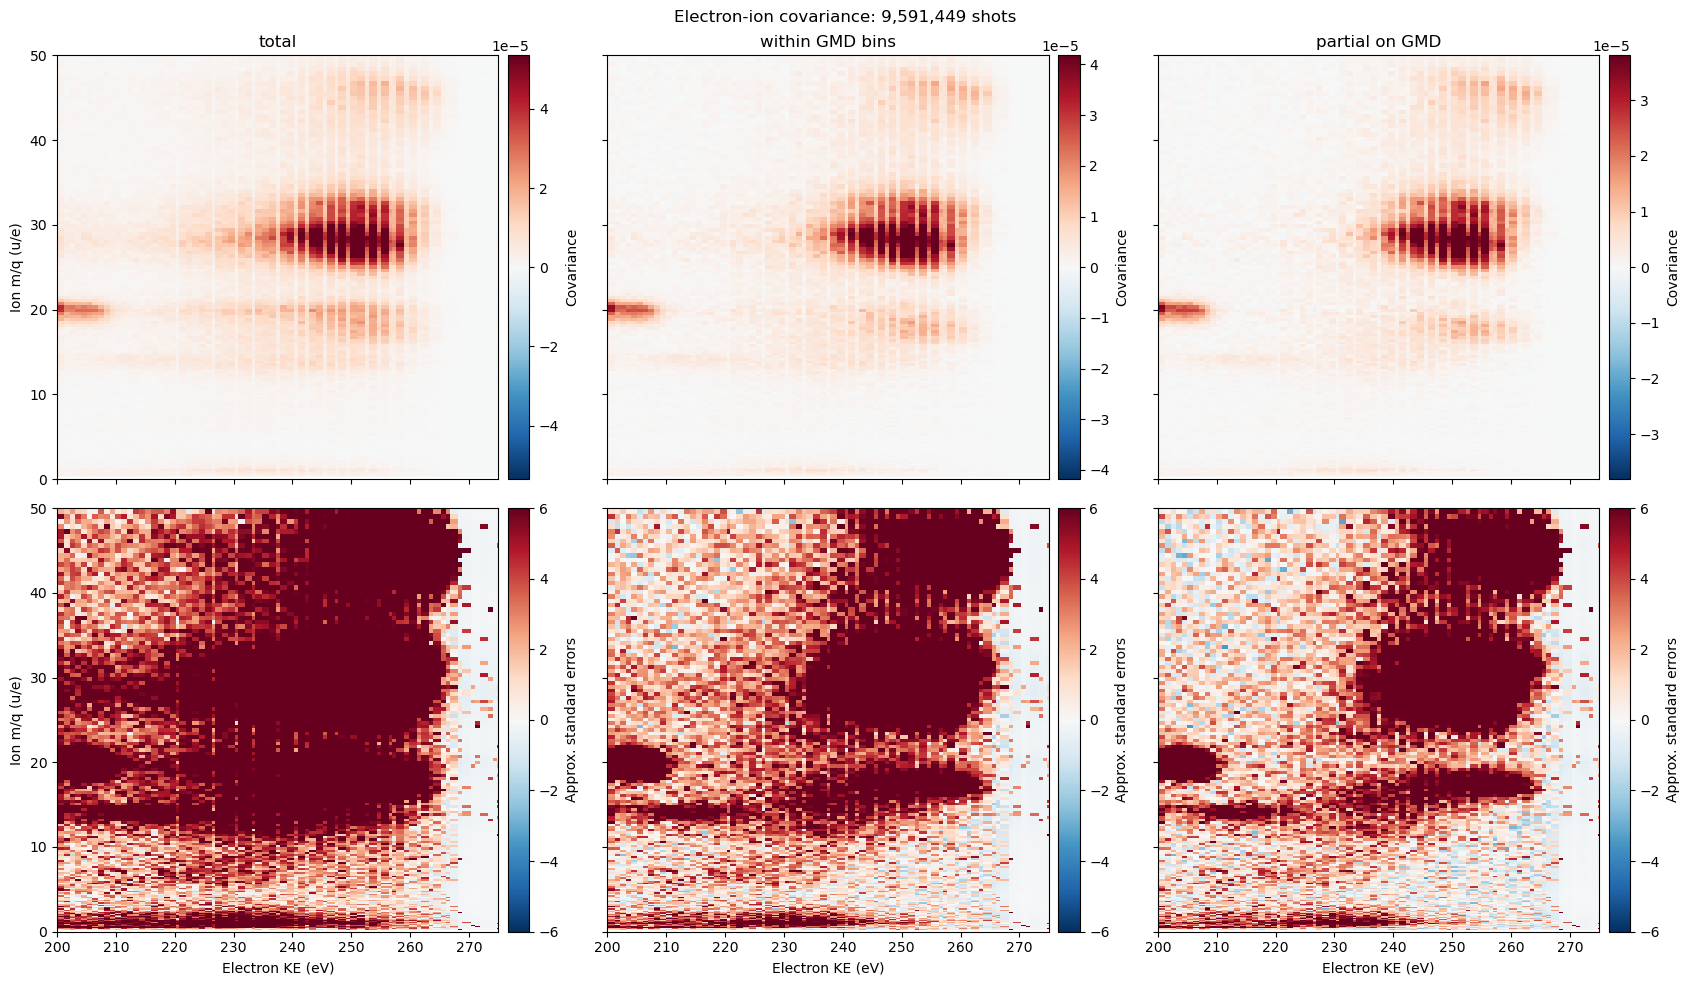

In [29]:
# ---- Delay-integrated electron-ion covariance -------------------------------

fig, ax = plt.subplots(2, 3, figsize=(17, 10),
                       sharex=True, sharey=True)

inside_e = ((cov_ke >= COV_KE_LIM[0]) &
            (cov_ke <= COV_KE_LIM[1]))

inside_i = ((cov_mq >= COV_MQ_LIM[0]) &
            (cov_mq <= COV_MQ_LIM[1]))

for k, (name, E) in enumerate(EST_AV.items()):

    M = E['DC']

    vmax = np.nanpercentile(
        np.abs(M[np.ix_(inside_e, inside_i)]), CLIP_PCT)

    if not np.isfinite(vmax) or vmax == 0:
        vmax = 1.0

    show_cov_map(ax[0, k], M.T,
                 cov_ke_edges, cov_mq_edges,
                 vmax=vmax, label='Covariance')

    show_cov_map(ax[1, k], (M / E['se_DC']).T,
                 cov_ke_edges, cov_mq_edges,
                 vmax=Z_MAX, label='Approx. standard errors')

    ax[0, k].set_title(name)
    ax[1, k].set_xlabel('Electron KE (eV)')

for a in ax[:, 0]:
    a.set_ylabel('Ion m/q (u/e)')

for a in ax.flat:
    a.set(xlim=COV_KE_LIM, ylim=COV_MQ_LIM)

fig.suptitle(f'Electron-ion covariance: {N:,.0f} shots')
fig.tight_layout()
plt.show()

### 9.5 Covariance-gated spectra

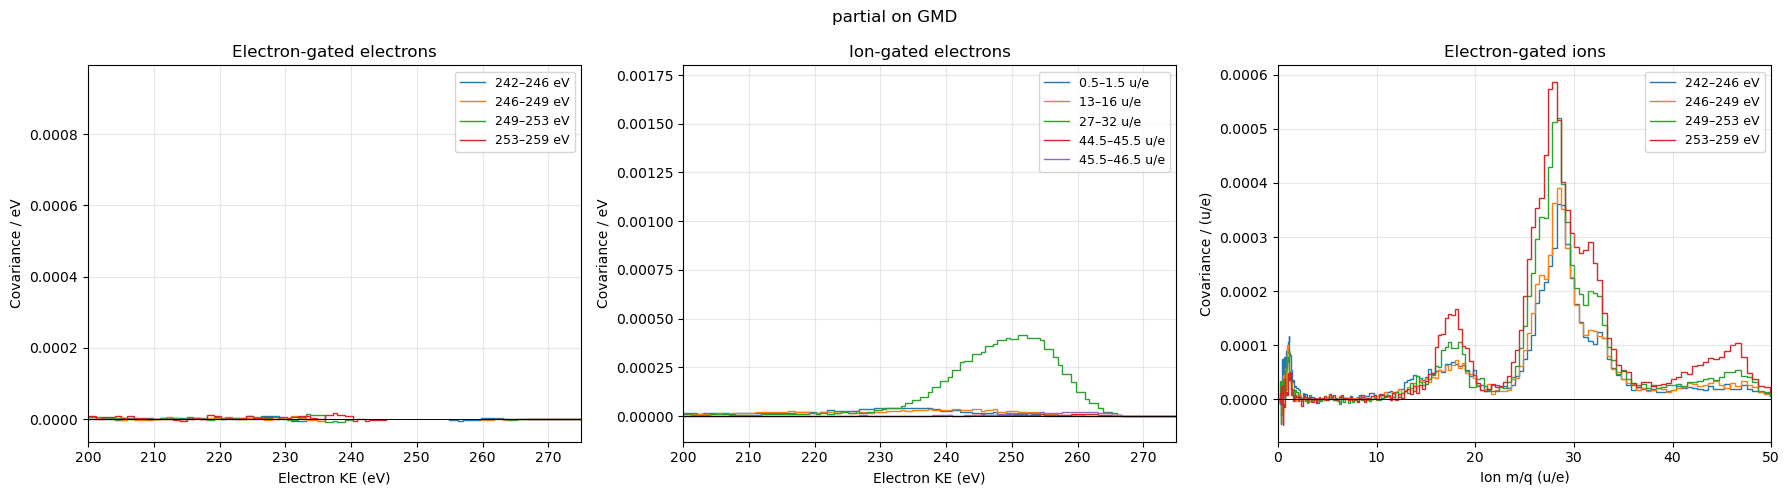

In [30]:
# ---- Covariance-filtered spectra --------------------------------------------

COV_E_WINDOWS = [
    (242, 246),    # Expected 5a photoelectron at 268 eV
    (246, 249),    # Expected 6a photoelectron
    (249, 253),
    (253, 259)
]

COV_ION_WINDOWS = [
    (0.5, 1.5),
    (13, 16),
    (27, 32),
    (44.5, 45.5),
    (45.5, 46.5)
]

COV_DENSITY = True


def in_win(centres, lo, hi):
    return (centres >= lo) & (centres < hi)


def ee_gated(M, gate):

    # Sum covariance over electron 1, excluding the diagonal band.
    valid = gate[:, None] & ~band

    spectrum = np.sum(np.where(valid, M, 0), axis=-2)
    spectrum[..., ~valid.any(axis=0)] = np.nan

    return spectrum


E = EST_AV[WINDOW_EST]

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# Electron spectra covarying with selected electrons.
for lo, hi in COV_E_WINDOWS:

    gate = in_win(cov_ke, lo, hi)
    if not gate.any():
        continue

    spectrum = ee_gated(E['DD'], gate)

    if COV_DENSITY:
        spectrum = spectrum / cov_dke

    ax[0].stairs(spectrum, cov_ke_edges, label=f'{lo}–{hi} eV')


# Electron spectra covarying with selected ions.
for lo, hi in COV_ION_WINDOWS:

    gate = in_win(cov_mq, lo, hi)
    if not gate.any():
        continue

    spectrum = E['DC'][:, gate].sum(axis=1)

    if COV_DENSITY:
        spectrum = spectrum / cov_dke

    ax[1].stairs(spectrum, cov_ke_edges, label=f'{lo}–{hi} u/e')


# Ion spectra covarying with selected electrons.
for lo, hi in COV_E_WINDOWS:

    gate = in_win(cov_ke, lo, hi)
    if not gate.any():
        continue

    spectrum = E['DC'][gate, :].sum(axis=0)

    if COV_DENSITY:
        spectrum = spectrum / cov_dmq

    ax[2].stairs(spectrum, cov_mq_edges, label=f'{lo}–{hi} eV')


ax[0].set(title='Electron-gated electrons',
          xlabel='Electron KE (eV)', xlim=COV_KE_LIM)

ax[1].set(title='Ion-gated electrons',
          xlabel='Electron KE (eV)', xlim=COV_KE_LIM)

ax[2].set(title='Electron-gated ions',
          xlabel='Ion m/q (u/e)', xlim=COV_MQ_LIM)

for k, a in enumerate(ax):
    ylabel = 'Covariance'
    if COV_DENSITY:
        ylabel += ' / eV' if k < 2 else ' / (u/e)'

    a.set_ylabel(ylabel)
    a.axhline(0, color='k', lw=0.7)
    a.legend(fontsize=9)
    a.grid(alpha=0.3)

fig.suptitle(WINDOW_EST)
fig.tight_layout()
plt.show()

### 9.6 Time-dependent covariance-gated spectra

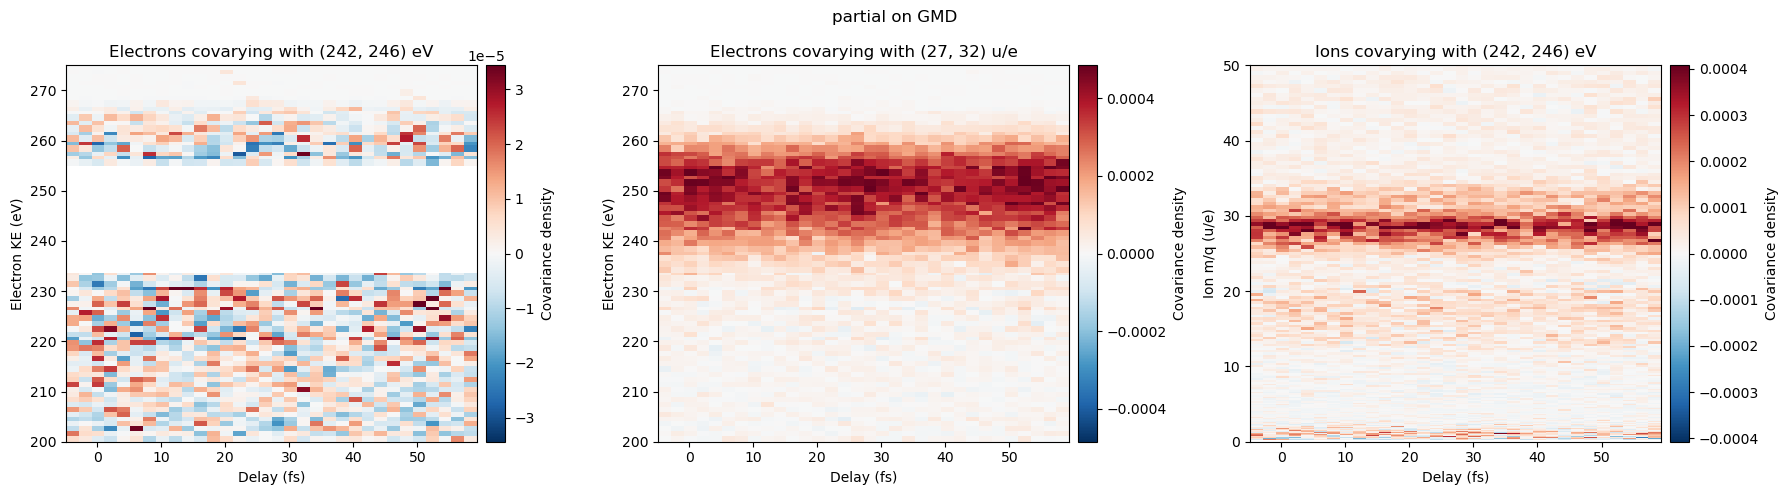

In [31]:
# ---- Time-dependent covariance-gated spectra -------------------------------

E_GATE = (242, 246)       # Expected 5a photoelectron
I_GATE = (27, 32)         # Example ethanol fragment region

E = EST[WINDOW_EST]

gate_e = in_win(cov_ke, *E_GATE)
gate_i = in_win(cov_mq, *I_GATE)

if not gate_e.any() or not gate_i.any():
    raise ValueError('No bins in the selected gate')


# Delay x electron KE
Y_ee_cov = ee_gated(E['DD'], gate_e)

# Delay x electron KE
Y_ie_cov = E['DC'][:, :, gate_i].sum(axis=2)

# Delay x ion m/q
Y_ei_cov = E['DC'][:, gate_e, :].sum(axis=1)


fig, ax = plt.subplots(1, 3, figsize=(18, 5), sharex=True)

for a, Y, edges, widths, centres, ylim, title, ylabel in zip(
    ax,
    [Y_ee_cov, Y_ie_cov, Y_ei_cov],
    [cov_ke_edges, cov_ke_edges, cov_mq_edges],
    [cov_dke, cov_dke, cov_dmq],
    [cov_ke, cov_ke, cov_mq],
    [COV_KE_LIM, COV_KE_LIM, COV_MQ_LIM],
    [
        f'Electrons covarying with {E_GATE} eV',
        f'Electrons covarying with {I_GATE} u/e',
        f'Ions covarying with {E_GATE} eV'
    ],
    ['Electron KE (eV)', 'Electron KE (eV)', 'Ion m/q (u/e)']
):

    M = Y / widths if COV_DENSITY else Y

    inside = (centres >= ylim[0]) & (centres <= ylim[1])

    vmax = np.nanpercentile(np.abs(M[:, inside]), CLIP_PCT)

    if not np.isfinite(vmax) or vmax == 0:
        vmax = 1.0

    show_cov_map(a, M.T, delay_edges, edges,
                 vmax=vmax, label='Covariance density'
                 if COV_DENSITY else 'Covariance')

    a.set(xlabel='Delay (fs)', ylabel=ylabel,
          ylim=ylim, title=title)

fig.suptitle(WINDOW_EST)
fig.tight_layout()
plt.show()

### 9.7 Temporal traces of selected covariance regions

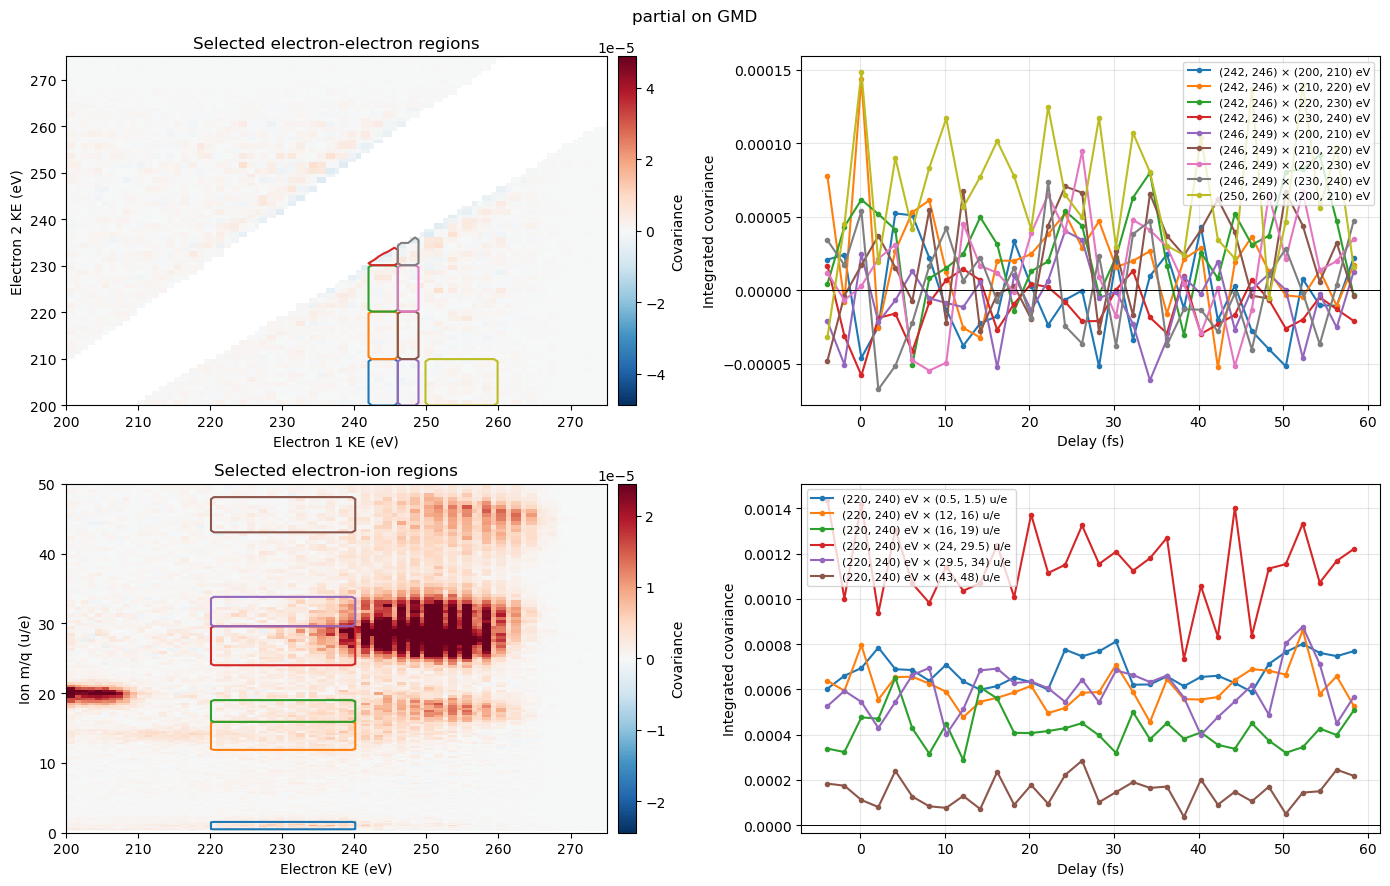

In [32]:
EE_ROIS = [  # Both candidate inner-valence holes
    # 5a hole — expected photoelectron at 244.0 eV
    ((242, 246), (200, 210)),
    ((242, 246), (210, 220)),
    ((242, 246), (220, 230)),
    ((242, 246), (230, 240)),

    # 6a hole — expected photoelectron at 247.3 eV
    ((246, 249), (200, 210)),
    ((246, 249), (210, 220)),
    ((246, 249), (220, 230)),
    ((246, 249), (230, 240)),

    ((250, 260), (200, 210))     #Away from photopeaks
]

EI_ROIS = [                     # Same electron window, different ion features
    ((220, 240), (0.5, 1.5)),
    ((220, 240), (12, 16)),
    ((220, 240), (16, 19)),
    ((220, 240), (24, 29.5)),
    ((220, 240), (29.5, 34)),
    ((220, 240), (43, 48))]

COV_NORMALISE_GMD = False

E = EST[WINDOW_EST]

fig, ax = plt.subplots(2, 2, figsize=(14, 9))

cov_traces = {}


# Electron-electron covariance regions.
M = np.where(band, np.nan, EST_AV[WINDOW_EST]['DD'])

show_cov_map(ax[0, 0], M, cov_ke_edges, cov_ke_edges,
             label='Covariance')

X, Y = np.meshgrid(cov_ke, cov_ke, indexing='ij')

for j, (win1, win2) in enumerate(EE_ROIS):

    gate1 = in_win(cov_ke, *win1)
    gate2 = in_win(cov_ke, *win2)

    roi = (gate1[:, None] & gate2[None, :]) & ~band

    if not roi.any():
        print('Empty covariance ROI; skipped')
        continue

    if np.any(gate1 & gate2):
        raise ValueError('Use non-overlapping electron windows')

    signal = E['DD'][:, roi].sum(axis=1)

    if COV_NORMALISE_GMD:
        signal = divide(signal, mean_G_cov)

    label = f'{win1} × {win2} eV'
    cov_traces['EE', win1, win2] = signal

    ax[0, 0].contour(X, Y, roi.astype(float),
                     levels=[0.5], colors=[f'C{j}'])

    ax[0, 1].plot(delay, signal, '.-',
                  color=f'C{j}', label=label)


# Electron-ion covariance regions.
show_cov_map(ax[1, 0], EST_AV[WINDOW_EST]['DC'].T,
             cov_ke_edges, cov_mq_edges,
             label='Covariance')

X, Y = np.meshgrid(cov_ke, cov_mq, indexing='ij')

for j, (win_e, win_i) in enumerate(EI_ROIS):

    gate_e = in_win(cov_ke, *win_e)
    gate_i = in_win(cov_mq, *win_i)

    roi = gate_e[:, None] & gate_i[None, :]

    if not roi.any():
        print('Empty covariance ROI; skipped')
        continue

    signal = E['DC'][:, roi].sum(axis=1)

    if COV_NORMALISE_GMD:
        signal = divide(signal, mean_G_cov)

    label = f'{win_e} eV × {win_i} u/e'
    cov_traces['EI', win_e, win_i] = signal

    ax[1, 0].contour(X, Y, roi.astype(float),
                     levels=[0.5], colors=[f'C{j}'])

    ax[1, 1].plot(delay, signal, '.-',
                  color=f'C{j}', label=label)


ax[0, 0].set(xlabel='Electron 1 KE (eV)',
             ylabel='Electron 2 KE (eV)',
             xlim=COV_KE_LIM, ylim=COV_KE_LIM,
             title='Selected electron-electron regions')

ax[1, 0].set(xlabel='Electron KE (eV)',
             ylabel='Ion m/q (u/e)',
             xlim=COV_KE_LIM, ylim=COV_MQ_LIM,
             title='Selected electron-ion regions')

for a in ax[:, 1]:

    a.set(xlabel='Delay (fs)',
          ylabel='Integrated covariance / GMD'
          if COV_NORMALISE_GMD else 'Integrated covariance')

    a.axhline(0, color='k', lw=0.7)
    a.legend(fontsize=8)
    a.grid(alpha=0.3)

fig.suptitle(WINDOW_EST)
fig.tight_layout()
plt.show()

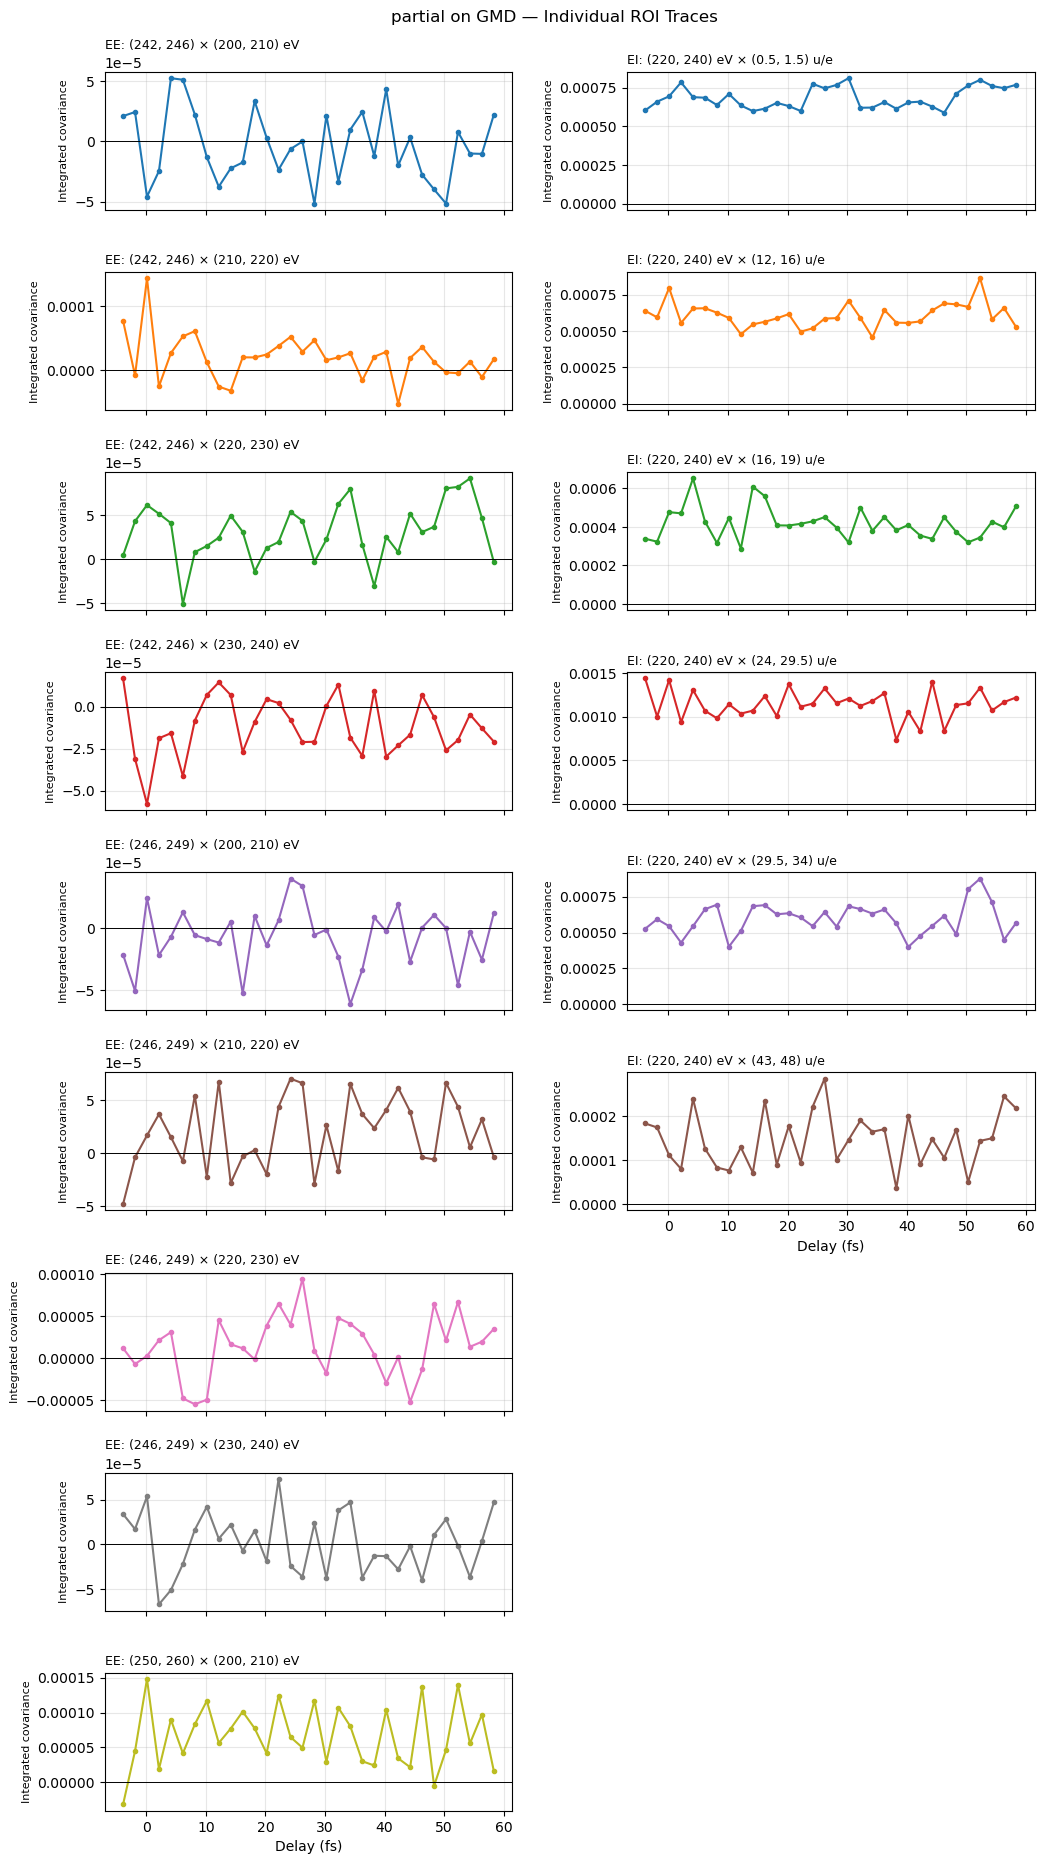

In [33]:
import matplotlib.gridspec as gridspec

# ---- Stacked temporal traces: Column 0 = EE ROIs, Column 1 = EI ROIs ------

ee_items = [
    (('EE', win1, win2), f'{win1} × {win2} eV', j)
    for j, (win1, win2) in enumerate(EE_ROIS)
    if ('EE', win1, win2) in cov_traces
]

ei_items = [
    (('EI', win_e, win_i), f'{win_e} eV × {win_i} u/e', j)
    for j, (win_e, win_i) in enumerate(EI_ROIS)
    if ('EI', win_e, win_i) in cov_traces
]

n_ee = len(ee_items)
n_ei = len(ei_items)
n_rows = max(n_ee, n_ei, 1)

ylabel_trace = (
    'Covariance / GMD' if COV_NORMALISE_GMD else 'Integrated covariance'
)

fig = plt.figure(figsize=(12, 2.3 * n_rows))
gs = gridspec.GridSpec(n_rows, 2, figure=fig, hspace=0.45, wspace=0.28)

for r, (key, label, color_idx) in enumerate(ee_items):
  ax_t = fig.add_subplot(gs[r, 0])
  ax_t.plot(delay, cov_traces[key], '.-', color=f'C{color_idx}')
  ax_t.set_title(f'EE: {label}', fontsize=9, loc='left')
  ax_t.set_ylabel(ylabel_trace, fontsize=8)
  ax_t.axhline(0, color='k', lw=0.7)
  ax_t.grid(alpha=0.3)
  if r < n_ee - 1:
    ax_t.set_xticklabels([])
  else:
    ax_t.set_xlabel('Delay (fs)')

for r, (key, label, color_idx) in enumerate(ei_items):
  ax_t = fig.add_subplot(gs[r, 1])
  ax_t.plot(delay, cov_traces[key], '.-', color=f'C{color_idx}')
  ax_t.set_title(f'EI: {label}', fontsize=9, loc='left')
  ax_t.set_ylabel(ylabel_trace, fontsize=8)
  ax_t.axhline(0, color='k', lw=0.7)
  ax_t.grid(alpha=0.3)
  if r < n_ei - 1:
    ax_t.set_xticklabels([])
  else:
    ax_t.set_xlabel('Delay (fs)')

fig.suptitle(f'{WINDOW_EST} — Individual ROI Traces')
fig.subplots_adjust(top=0.95)
plt.show()

### 9.8 Run-by-run electron–electron covariance and pair statistics

A selected pair of electron windows is checked separately in each scan. This cell reads only the relevant blocks of the second moments. It retains the original, more conservative dead-time mask: the minimum separation between the two original TOF bins must exceed `DEAD_TIME_NS`. It therefore need not give exactly the same result as the centre-based mask in the maps above (or if the maps are rebinned). The pair count is the detected same-shot pair moment, before accidental-background subtraction.

Photoelectron ROI: (242, 246) eV
Second electron ROI: (220, 230) eV
Dead-time mask: 2.0 ns
ROI pixels retained: 97.5%
Files selected: 4

Ethanol_delay_scan_long_1_268eV_2808353754_aggregates_tr.h5
  Shots: 2,414,666
  Detected pairs: 1,204
Ethanol_delay_scan_long_2_268eV_2808380252_aggregates_tr.h5
  Shots: 2,407,157
  Detected pairs: 1,286
Ethanol_delay_scan_long_3_268eV_2808406908_aggregates_tr.h5
  Shots: 2,330,025
  Detected pairs: 1,125
Ethanol_delay_scan_long_4_268eV_2808435816_aggregates_tr.h5
  Shots: 2,439,601
  Detected pairs: 1,784


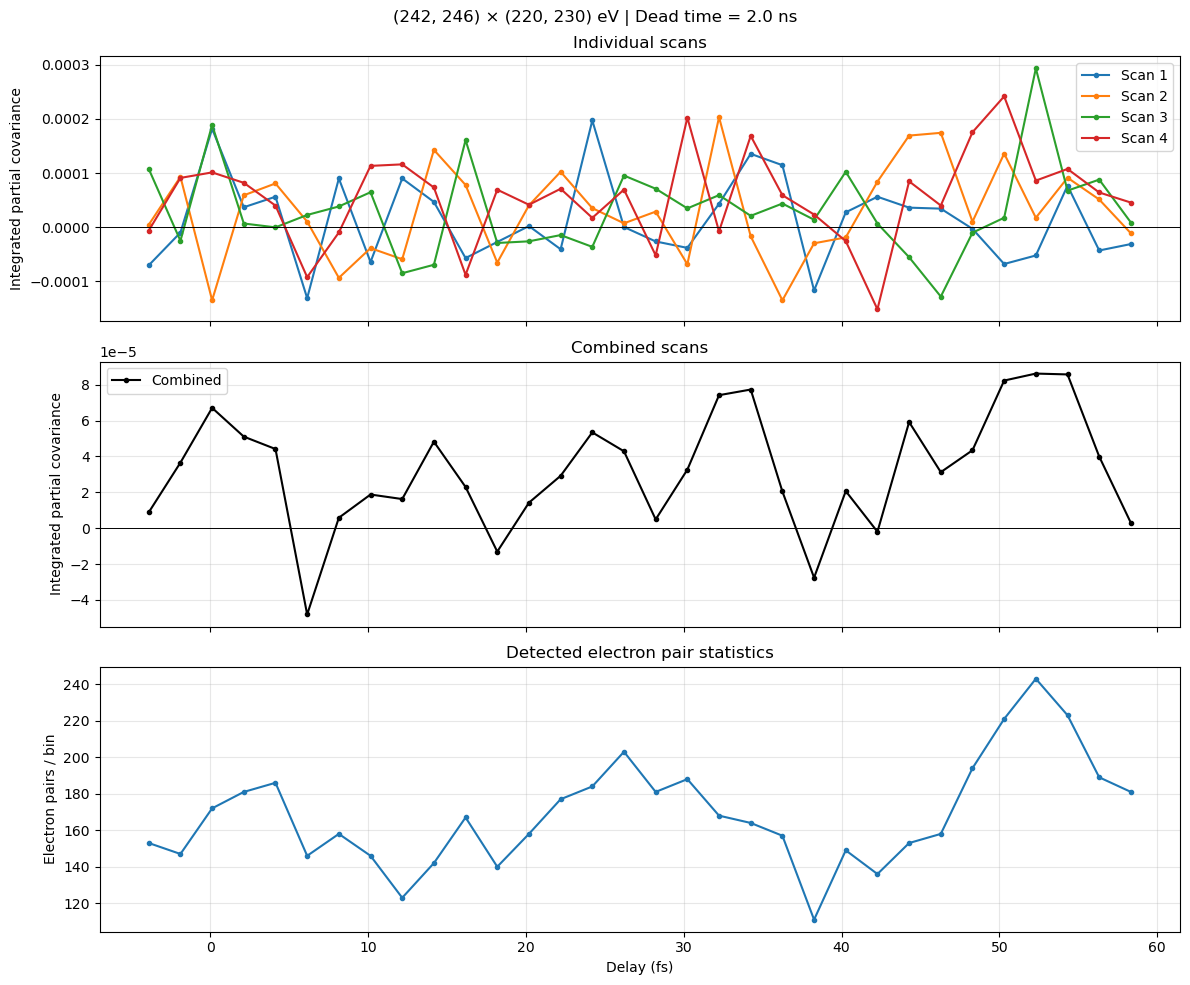


Total shots: 9,591,449
Total detected pairs: 5,399


In [34]:
# ---- Parameters --------------------------------------------------------

files = COV_FILES
PHOTOELECTRON_ROI = (242, 246)
PAIR_SECOND_ROI = (220, 230)

# ---- Calibrated axes ---------------------------------------------------

with h5py.File(files[0], 'r') as f:
    pair_tof_edges = f['tof_edges'][:] / 10
    pair_z_edges = f['z_edges'][:]

pair_ke_edges = calibration.ke_of_tof(pair_tof_edges)
pair_ke = (pair_ke_edges[:-1] + pair_ke_edges[1:]) / 2

pair_delay_edges = DELAY_SIGN * (pair_z_edges - Z_ZERO) * FS_PER_STAGE_UNIT
pair_delay = (pair_delay_edges[:-1] + pair_delay_edges[1:]) / 2

# Select the electron gates in the original TOF axis order.
gate1 = (pair_ke >= PHOTOELECTRON_ROI[0]) & (pair_ke < PHOTOELECTRON_ROI[1])
gate2 = (pair_ke >= PAIR_SECOND_ROI[0]) & (pair_ke < PAIR_SECOND_ROI[1])

idx1 = np.flatnonzero(gate1)
idx2 = np.flatnonzero(gate2)

if not idx1.size or not idx2.size:
    raise ValueError('Empty electron gate')

sl1 = slice(idx1[0], idx1[-1] + 1)
sl2 = slice(idx2[0], idx2[-1] + 1)

# ---- Dead-time mask ----------------------------------------------------

tof_lo = np.minimum(pair_tof_edges[:-1], pair_tof_edges[1:])
tof_hi = np.maximum(pair_tof_edges[:-1], pair_tof_edges[1:])

min_dt = np.maximum(
    tof_lo[sl1, None] - tof_hi[None, sl2],
    tof_lo[None, sl2] - tof_hi[sl1, None])

min_dt = np.maximum(min_dt, 0)

roi = min_dt > DEAD_TIME_NS

if not roi.any():
    raise ValueError('Entire ROI excluded by dead-time mask')

print(f'Photoelectron ROI: {PHOTOELECTRON_ROI} eV')
print(f'Second electron ROI: {PAIR_SECOND_ROI} eV')
print(f'Dead-time mask: {DEAD_TIME_NS} ns')
print(f'ROI pixels retained: {100 * roi.mean():.1f}%')
print(f'Files selected: {len(files)}\n')

# ---- Calculate covariance independently for each scan -------------------

results = {}

for path in files:

    cov_sum = np.zeros(len(pair_delay))
    shot_sum = np.zeros(len(pair_delay))
    pair_sum = np.zeros(len(pair_delay))

    with h5py.File(path, 'r') as f:

        if (not np.array_equal(f['z_edges'][:], pair_z_edges)
            or not np.array_equal(f['tof_edges'][:] / 10, pair_tof_edges)):
            raise ValueError(f'{path.name}: incompatible bin edges')

        n = f['n_per_bin'][:]

        bins = range(n.shape[0]) if COV_GMD_BINS is None else COV_GMD_BINS

        for j in bins:
            for k in range(len(pair_delay)):

                N = n[j, k]

                if N < MIN_COV_SHOTS:
                    continue

                # First moments.
                D1 = f['D'][j, k, sl1].astype(float)
                D2 = f['D'][j, k, sl2].astype(float)
                G = float(f['G'][j, k])

                # Second moments: load only the selected ROI.
                DD = f['DtD'][j, k, sl1, sl2].astype(float)
                D1G = f['DtG'][j, k, sl1].astype(float)
                D2G = f['DtG'][j, k, sl2].astype(float)
                GG = float(f['GtG'][j, k])

                var_G = GG - G**2

                if not np.isfinite(var_G) or var_G <= 0:
                    continue

                # Ordinary covariance.
                cov_DD = DD - np.outer(D1, D2)

                # Covariance with GMD.
                cov_D1G = D1G - D1 * G
                cov_D2G = D2G - D2 * G

                # Partial covariance on GMD.
                pcov = cov_DD - np.outer(cov_D1G, cov_D2G) / var_G

                # Integrate the unmasked ROI and weight by shots.
                cov_sum[k] += N * pcov[roi].sum()
                pair_sum[k] += N * DD[roi].sum()
                shot_sum[k] += N

    trace = np.divide(
        cov_sum, shot_sum,
        out=np.full(len(pair_delay), np.nan),
        where=shot_sum > 0)

    results[path.name] = dict(
        trace=trace,
        cov_sum=cov_sum,
        shots=shot_sum,
        pairs=pair_sum)

    print(path.name)
    print(f'  Shots: {shot_sum.sum():,.0f}')
    print(f'  Detected pairs: {pair_sum.sum():,.0f}')

# ---- Combine scans -----------------------------------------------------

total_cov = np.sum([r['cov_sum'] for r in results.values()], axis=0)
total_shots = np.sum([r['shots'] for r in results.values()], axis=0)
total_pairs = np.sum([r['pairs'] for r in results.values()], axis=0)

combined_trace = np.divide(
    total_cov, total_shots,
    out=np.full(len(pair_delay), np.nan),
    where=total_shots > 0)

order = np.argsort(pair_delay)

# ---- Plot temporal traces ----------------------------------------------

fig, ax = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

for j, (name, r) in enumerate(results.items()):

    ax[0].plot(pair_delay[order], r['trace'][order], '.-',
               label=f'Scan {j+1}')

ax[1].plot(pair_delay[order], combined_trace[order], 'k.-',
           label='Combined')

ax[2].plot(pair_delay[order], total_pairs[order], '.-',
           color='C0')

ax[0].set_title('Individual scans')
ax[1].set_title('Combined scans')
ax[2].set_title('Detected electron pair statistics')

ax[0].set_ylabel('Integrated partial covariance')
ax[1].set_ylabel('Integrated partial covariance')
ax[2].set_ylabel('Electron pairs / bin')
ax[2].set_xlabel('Delay (fs)')

for a in ax[:2]:
    a.axhline(0, color='k', lw=0.7)
    a.legend()

for a in ax:
    a.grid(alpha=0.3)

fig.suptitle(
    f'{PHOTOELECTRON_ROI} × {PAIR_SECOND_ROI} eV | '
    f'Dead time = {DEAD_TIME_NS} ns')

fig.tight_layout()
plt.show()

print(f'\nTotal shots: {total_shots.sum():,.0f}')
print(f'Total detected pairs: {total_pairs.sum():,.0f}')

ee_roi_results = dict(delay=pair_delay[order],
                      scans={name: {key: value[order] for key, value in r.items()}
                             for name, r in results.items()},
                      combined=combined_trace[order],
                      shots=total_shots[order],
                      pairs=total_pairs[order])